# Actividad 2: Red Neuronal Convolucional sobre un dataset de imágenes reales

**Universidad Nacional del Centro del Perú**
**Facultad de Ingeniería de Sistemas**

## A. Presentación

**Curso:** Ingeniería del Conocimiento (ISO56B)
**Semestre:** 2026-II
**Fecha:** 23-10-2026

**Integrantes:**

| Nombre | Código |
|---|---|
| Gutierrez Vega Bill Toño | 2012100229F |
| Quispealaya Vera Elias Carlos | 2024200203H |
| López Granados Karito Dali Yoselyn | 2024200191I |
| Paredes Huarcaya Michael | 202420025F |

**Dataset:** Mineral Photos
**Fuente:** https://www.kaggle.com/datasets/floriangeillon/mineral-photos

**Justificación de la elección:** Se eligió *Mineral Photos* porque cumple todos los requisitos de la actividad: es un problema de clasificación de imágenes, tiene 39,354 fotografías (muy por encima del mínimo de 1,000), 15 clases (el mínimo es 3), son fotos reales de especímenes y no se ha usado en el curso. Además, ofrece un reto realista y no saturado: muchas especies minerales son visualmente parecidas (varias son incoloras, blancas o translúcidas), lo que permite analizar confusiones por similitud visual y no solo reportar una accuracy alta. Las imágenes tienen fondos, iluminación y encuadres muy variados, y las clases están desbalanceadas (de 1,188 a 8,244 imágenes por clase), lo que obliga a tomar decisiones de preprocesamiento (eliminar duplicados, balancear, dividir con estratificación) y hace significativo evaluar con métricas por clase. Por último, el tema es cercano a nuestra realidad: el Perú es un país con gran actividad minera, y reconocer minerales a partir de fotos tiene aplicaciones en geología, educación y exploración.

**Problema de clasificación:** dada una fotografía de un espécimen mineral, el modelo debe identificar a cuál de 15 especies pertenece (azurita, baritina, berilo, calcita, cerusita, cobre, fluorita, yeso, hematita, malaquita, pirita, piromorfita, cuarzo, smithsonita y wulfenita). Es un problema de clasificación multiclase sobre 39,354 imágenes. Las clases están desbalanceadas (de 1,188 a 8,244 imágenes por clase).

**Uso de GPU:** el entrenamiento se hizo en la GPU local NVIDIA GeForce RTX 5060 Laptop (8 GB), no en la T4 de Colab. Se usó Keras 3 con PyTorch como backend.

---
**Términos técnicos:**
- **CNN (red neuronal convolucional):** red que aprende filtros sobre la imagen para detectar bordes, texturas y formas.
- **Clasificación multiclase:** cada imagen pertenece a una sola categoría entre varias.
- **Backend de Keras:** el motor que ejecuta los cálculos de la red; aquí PyTorch, porque soporta la GPU RTX 5060.
- **GPU:** procesador con miles de núcleos que hace en paralelo las multiplicaciones que exige entrenar una red.

### Configuración del entorno

`KERAS_BACKEND` indica qué motor hace los cálculos de la red (aquí PyTorch, porque soporta la GPU RTX 5060); debe definirse **antes** de importar Keras. `keras.utils.set_random_seed` fija la semilla de Python, NumPy y del backend para que los resultados sean reproducibles. `torch.cuda.is_available()` confirma que la GPU está activa.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # debe ir ANTES de importar keras

import keras, torch

SEED = 42
keras.utils.set_random_seed(SEED)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("GPU disponible:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna")

Keras: 3.15.1 | backend: torch
GPU disponible: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## B. Carga, exploración y preprocesamiento

### Importaciones y parámetros

Se concentran aquí los parámetros que condicionan toda la sección:
- `DATA_DIR`: carpeta con las 15 subcarpetas de minerales (solo se usa `dataset/data/data`).
- `IMG_SIZE`: lado en píxeles al que se reducen las imágenes (las fotos originales son más grandes; reducirlas acelera el entrenamiento).
- `MAX_POR_CLASE`: tope de imágenes por clase para balancear. `"min"` iguala todas las clases a la más pequeña tras quitar duplicados; un número fija el tope a mano; `None` no balancea.
- `TEST_SIZE` y `VAL_SIZE`: proporción de test (sobre el total) y de validación (sobre el train).
- `SEED`: semilla del azar, para que los resultados sean reproducibles.

Librerías nuevas: `pathlib.Path` maneja rutas de archivos; `pandas.DataFrame` es una tabla; `PIL.Image` abre y redimensiona imágenes; `train_test_split` (scikit-learn) divide datos al azar; `ThreadPoolExecutor` ejecuta varias tareas en paralelo; `hashlib` calcula huellas digitales de datos.

In [2]:
import os, time, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", message=".*malformed MPO.*")   # aviso inofensivo de algunos JPEG
ImageFile.LOAD_TRUNCATED_IMAGES = True                           # carga archivos incompletos en vez de fallar

# La ruta del proyecto se lee del archivo .env (variable PROYECTO).
# Si no existe .env, se usa la carpeta desde la que se abre el notebook.
load_dotenv(find_dotenv(usecwd=True))
PROYECTO = Path(os.getenv("PROYECTO", Path.cwd()))
DATA_DIR = PROYECTO / "dataset" / "data" / "data"
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset en: {DATA_DIR}\n"
        "Descárgalo desde Kaggle y colócalo en dataset/data/data, "
        "o define PROYECTO en el archivo .env (ver .env.example)."
    )
print("Proyecto:", PROYECTO)

SEED = 42
IMG_SIZE = 128
MAX_POR_CLASE = "min"     # "min" = igualar clases a la más pequeña | número | None = no balancear
TEST_SIZE = 0.20
VAL_SIZE = 0.10

Proyecto: D:\ingeniería de sistemas\semestre 5\ingenieria del conocimiento\actividad2


### B.1 Cargar el dataset

El dataset se obtuvo por **descarga directa** desde Kaggle (`kagglehub`). Viene como una carpeta por mineral, sin separación en train y test. La carga se hace en cinco pasos: listar las imágenes (B.1.1), cargarlas a memoria (B.1.2), eliminar duplicados (B.1.3), balancear las clases (B.1.4) y crear los conjuntos train y test (B.1.5).

#### B.1.1 Listar las imágenes y sus etiquetas

Se recorre `DATA_DIR` con `os.walk` (visita todas las subcarpetas). El nombre de la carpeta es la **clase** de cada imagen. Se arma una tabla con la ruta y la clase, y se asigna a cada clase un número entero (0 a 14), porque `sparse_categorical_crossentropy` espera etiquetas enteras.

In [3]:
registros = []
for carpeta, _, archivos in os.walk(DATA_DIR):
    for a in archivos:
        if Path(a).suffix.lower() in EXT:
            registros.append((str(Path(carpeta) / a), Path(carpeta).name))

df_total = pd.DataFrame(registros, columns=["ruta", "clase"])
CLASES = sorted(df_total["clase"].unique())
clase_a_id = {c: i for i, c in enumerate(CLASES)}
assert len(CLASES) == 15, "Se esperaban 15 clases; revisa DATA_DIR"

print("Imágenes encontradas:", len(df_total), "| Clases:", len(CLASES))
print(df_total["clase"].value_counts().reindex(CLASES).to_string())

Imágenes encontradas: 39354 | Clases: 15
clase
azurite         1250
baryte          2211
beryl           1615
calcite         6574
cerussite       1367
copper          1429
fluorite        5669
gypsum          1351
hematite        1284
malachite       1607
pyrite          2339
pyromorphite    1705
quartz          8244
smithsonite     1188
wulfenite       1521


#### B.1.2 Cargar las imágenes a memoria

Cada imagen se abre, se convierte a RGB (3 canales de color), se redimensiona a `IMG_SIZE`×`IMG_SIZE` y se guarda como arreglo de NumPy de enteros de 8 bits (`uint8`, valores 0 a 255). `Image.draft` acelera la lectura de JPEG decodificándolos ya a menor tamaño. `ThreadPoolExecutor` procesa varias imágenes a la vez. Si un archivo está dañado, `try/except` lo descarta; una máscara booleana (`ok`) indica cuáles se cargaron. `np.stack` apila las imágenes en un solo arreglo de forma (N, alto, ancho, 3).

El resultado se guarda en disco con `np.save` (caché): la primera vez tarda unos minutos y las siguientes, segundos.

In [4]:
CACHE_X = PROYECTO / f"cache_data_{IMG_SIZE}px.npy"
CACHE_OK = PROYECTO / f"cache_data_{IMG_SIZE}px_ok.npy"

def cargar_imagen(ruta):
    try:
        with Image.open(ruta) as im:
            im.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))
            im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
            return np.asarray(im, dtype=np.uint8)
    except Exception:
        return None

if CACHE_X.exists() and CACHE_OK.exists():
    X_pool, ok_pool = np.load(CACHE_X), np.load(CACHE_OK)
    print("Cargado desde caché")
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=16) as ex:
        res = list(ex.map(cargar_imagen, df_total["ruta"]))
    ok_pool = np.array([r is not None for r in res])
    X_pool = np.stack([r for r in res if r is not None])
    np.save(CACHE_X, X_pool)
    np.save(CACHE_OK, ok_pool)
    print(f"Cargadas y guardadas en caché en {time.time() - t0:.0f} s")

assert len(ok_pool) == len(df_total), "La caché no coincide con el listado: borra los archivos cache_data_*"
df_pool = df_total[ok_pool].reset_index(drop=True)
assert len(X_pool) == len(df_pool)
print("Descartadas por archivo dañado:", int((~ok_pool).sum()))
print("X_pool:", X_pool.shape, X_pool.dtype)

Cargado desde caché
Descartadas por archivo dañado: 0
X_pool: (39354, 128, 128, 3) uint8


#### B.1.3 Eliminar imágenes duplicadas

Si una misma foto está en train y en test, el modelo la memoriza y la accuracy sale inflada. Por eso se eliminan los duplicados **antes** de balancear y dividir. Se calculan dos huellas por imagen:
- **Hash exacto (MD5):** mismos píxeles, misma huella.
- **Hash aproximado:** la imagen se reduce a 16×16 en grises y cada píxel se marca como más claro o más oscuro que el promedio (256 bits). Detecta copias casi idénticas.

Se eliminan (1) las imágenes cuya huella aparece con **etiquetas distintas** (contradictorias) y (2) las copias repetidas, conservando una sola. `groupby` agrupa filas por un valor, `drop_duplicates` conserva la primera aparición y `~` niega una condición booleana. No se detectan fotos distintas del mismo espécimen.

In [5]:
def hash_exacto(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

def hash_aprox(X, bloque=1000):
    salida, k = [], IMG_SIZE // 16
    for i in range(0, len(X), bloque):
        g = X[i:i + bloque].astype("float32").mean(axis=3)               # escala de grises
        p = g.reshape(len(g), 16, k, 16, k).mean(axis=(2, 4))            # reducción a 16x16
        bits = (p > p.mean(axis=(1, 2), keepdims=True)).reshape(len(p), -1)
        salida += [np.packbits(b).tobytes() for b in bits]
    return salida

df_pool["h_ex"] = hash_exacto(X_pool)
df_pool["h_ap"] = hash_aprox(X_pool)

print("Imágenes antes de limpiar:", len(df_pool))
print("Con hash exacto repetido     :", int(df_pool.duplicated("h_ex", keep=False).sum()))
print("Con hash aproximado repetido :", int(df_pool.duplicated("h_ap", keep=False).sum()))

# (1) Etiquetas contradictorias: misma huella en clases distintas
n_clases = df_pool.groupby("h_ap")["clase"].nunique()
contradictorias = n_clases[n_clases > 1].index
mantener = ~df_pool["h_ap"].isin(contradictorias)
print("Huellas con etiquetas contradictorias (se eliminan):", len(contradictorias))
df_pool, X_pool = df_pool[mantener].reset_index(drop=True), X_pool[mantener.to_numpy()]

# (2) Una sola imagen por huella
primera = ~df_pool["h_ap"].duplicated(keep="first")
X_unico = X_pool[primera.to_numpy()]
df_unico = df_pool[primera].reset_index(drop=True)
df_unico["y"] = df_unico["clase"].map(clase_a_id)
del X_pool

print("Imágenes únicas:", len(df_unico), "| eliminadas:", len(df_total) - len(df_unico))
comparacion = pd.DataFrame({
    "original": df_total["clase"].value_counts().reindex(CLASES),
    "únicas": df_unico["clase"].value_counts().reindex(CLASES),
})
comparacion["eliminadas"] = comparacion["original"] - comparacion["únicas"]
print(comparacion.to_string())

Imágenes antes de limpiar: 39354
Con hash exacto repetido     : 14
Con hash aproximado repetido : 88
Huellas con etiquetas contradictorias (se eliminan): 3
Imágenes únicas: 39303 | eliminadas: 51
              original  únicas  eliminadas
clase                                     
azurite           1250    1243           7
baryte            2211    2206           5
beryl             1615    1613           2
calcite           6574    6557          17
cerussite         1367    1366           1
copper            1429    1429           0
fluorite          5669    5664           5
gypsum            1351    1350           1
hematite          1284    1282           2
malachite         1607    1606           1
pyrite            2339    2339           0
pyromorphite      1705    1704           1
quartz            8244    8236           8
smithsonite       1188    1187           1
wulfenite         1521    1521           0


#### B.1.4 Balanceo de clases

El dataset está muy desbalanceado (de 1,188 a 8,244 imágenes por clase). Un modelo entrenado así tendería a favorecer a las clases grandes, y la accuracy global ocultaría el mal desempeño en las pequeñas. Por eso, con las imágenes únicas, se limita cada clase al tamaño de la **más pequeña** (`value_counts().min()`), tomando una muestra al azar reproducible con `DataFrame.sample`. Así todas las clases quedan con el mismo número de imágenes y acertar al azar daría 1/15 ≈ 6.7%. La muestra se guarda como un arreglo de posiciones (`idx_bal`) que se usará en el paso siguiente.

In [6]:
conteo_unico = df_unico["clase"].value_counts()
if MAX_POR_CLASE == "min":
    TOPE = int(conteo_unico.min())
elif MAX_POR_CLASE is None:
    TOPE = int(conteo_unico.max())
else:
    TOPE = int(MAX_POR_CLASE)
print("Tope por clase aplicado:", TOPE, "| clase más pequeña:", conteo_unico.idxmin())

idx_bal = pd.concat([g.sample(min(len(g), TOPE), random_state=SEED)
                     for _, g in df_unico.groupby("clase")]).index.to_numpy()

df_bal = df_unico.loc[idx_bal]
print("Imágenes tras el balanceo:", len(df_bal))
print(df_bal["clase"].value_counts().reindex(CLASES).to_string())

Tope por clase aplicado: 1187 | clase más pequeña: smithsonite
Imágenes tras el balanceo: 17805
clase
azurite         1187
baryte          1187
beryl           1187
calcite         1187
cerussite       1187
copper          1187
fluorite        1187
gypsum          1187
hematite        1187
malachite       1187
pyrite          1187
pyromorphite    1187
quartz          1187
smithsonite     1187
wulfenite       1187


#### B.1.5 División train / test

Se separa el **20% como test** con `train_test_split(..., stratify=y)`, que mantiene la misma proporción de cada clase en ambos conjuntos (aquí todas las clases tienen el mismo tamaño, así que quedan iguales). Como los duplicados ya se eliminaron, ninguna imagen debe estar en train y test a la vez, y se comprueba comparando sus huellas. El test no se toca hasta la Sección F.

In [7]:
idx_tr, idx_te = train_test_split(
    idx_bal, test_size=TEST_SIZE, stratify=df_unico.loc[idx_bal, "y"], random_state=SEED
)

X_train, X_test = X_unico[idx_tr], X_unico[idx_te]
df_train = df_unico.loc[idx_tr].reset_index(drop=True)
df_test = df_unico.loc[idx_te].reset_index(drop=True)
y_train = df_train["y"].to_numpy(dtype="int64")
y_test = df_test["y"].to_numpy(dtype="int64")
del X_unico

fuga = len(set(df_train["h_ap"]) & set(df_test["h_ap"]))
print("Imágenes de test con copia en train:", fuga)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Imágenes de test con copia en train: 0
Train: (14244, 128, 128, 3) | Test: (3561, 128, 128, 3)


### B.2 Mostrar dimensiones

Se muestra el número de imágenes de train y test, la resolución con que quedaron y los canales. `shape` indica las dimensiones de un arreglo: (imágenes, alto, ancho, canales). Para conocer la resolución **original** se abre una muestra de 200 fotos con `Image.open`, que solo lee la cabecera y no decodifica la imagen, y se resumen sus tamaños (`np.median` es la mediana).

In [8]:
print("Imágenes de train:", X_train.shape[0], "| Imágenes de test:", X_test.shape[0])
print("Resolución usada:", X_train.shape[1], "x", X_train.shape[2], "| Canales:", X_train.shape[3], "(RGB)")

def tam_original(ruta):
    with Image.open(ruta) as im:
        return im.size   # (ancho, alto)

muestra = df_train["ruta"].sample(200, random_state=SEED)
tams = np.array([tam_original(r) for r in muestra])
print("\nResolución original (muestra de 200 fotos), ancho x alto:")
print("  mínima :", tams.min(axis=0))
print("  mediana:", np.median(tams, axis=0))
print("  máxima :", tams.max(axis=0))

Imágenes de train: 14244 | Imágenes de test: 3561
Resolución usada: 128 x 128 | Canales: 3 (RGB)

Resolución original (muestra de 200 fotos), ancho x alto:
  mínima : [400 227]
  mediana: [400. 400.]
  máxima : [2210 1928]


### B.3 Grilla de ejemplos

`plt.subplots(3, 5)` crea una cuadrícula de 3 filas × 5 columnas, una celda por clase. De cada clase se elige una imagen del train con `np.random.default_rng(SEED).choice` (aleatoria pero reproducible) y se muestra con `imshow`, con el nombre del mineral como título. `np.where` devuelve las posiciones que cumplen una condición. Sirve para revisar visualmente que las imágenes sean fotos reales y correspondan a su clase.

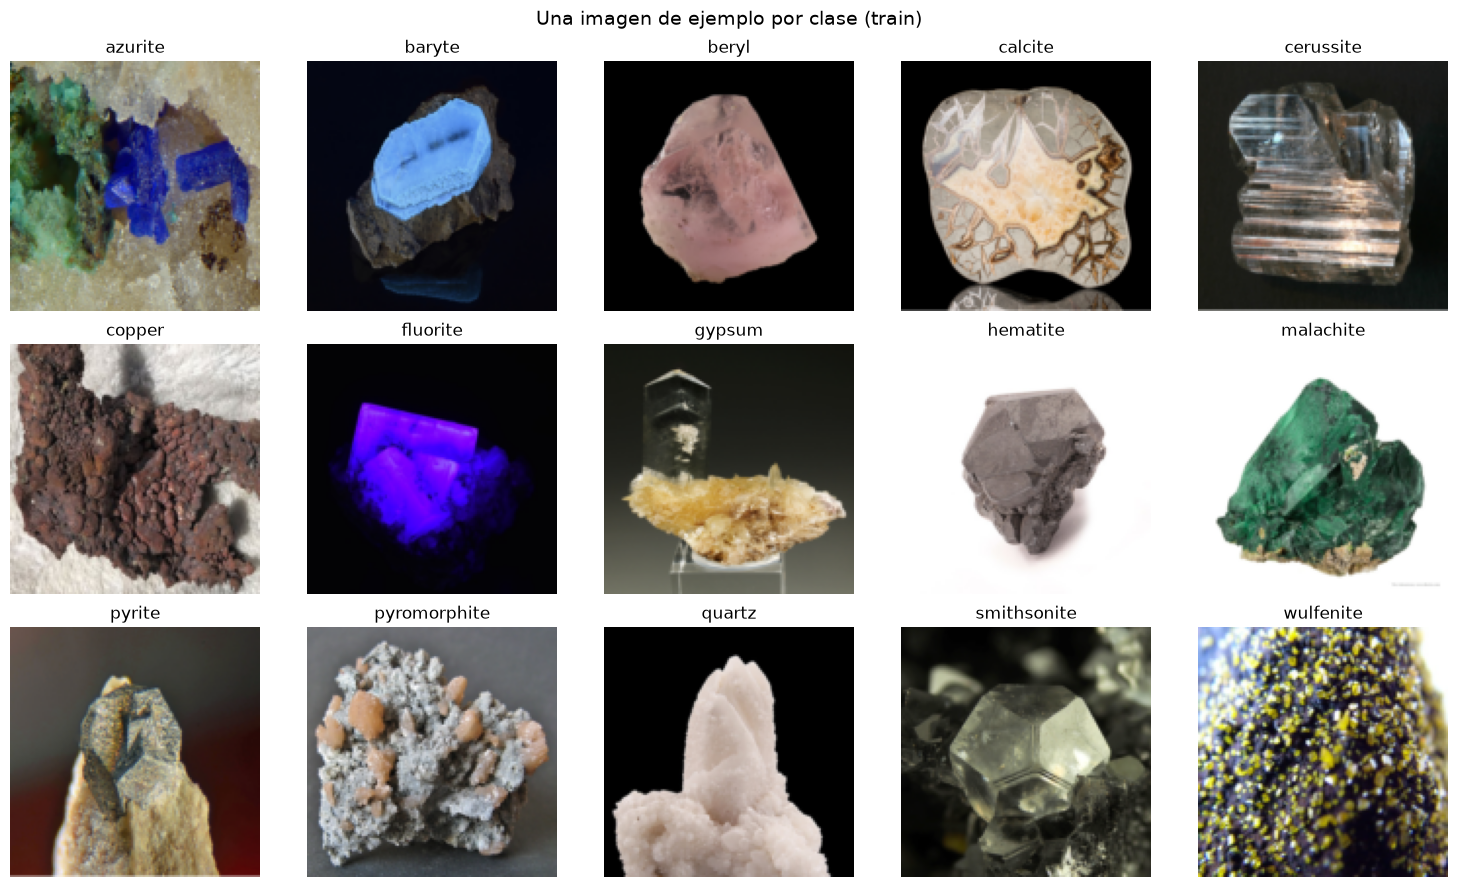

In [9]:
rng = np.random.default_rng(SEED)
fig, ejes = plt.subplots(3, 5, figsize=(15, 9))
for eje in ejes.ravel():
    eje.axis("off")

for i, nombre in enumerate(CLASES):
    j = rng.choice(np.where(y_train == i)[0])
    ejes.ravel()[i].imshow(X_train[j])
    ejes.ravel()[i].set_title(nombre)

plt.suptitle("Una imagen de ejemplo por clase (train)", fontsize=14)
plt.tight_layout()
plt.show()

### B.4 Distribución de clases

Gráfico de barras con el número de imágenes por clase en tres etapas: el dataset **original**, las imágenes **únicas** (sin duplicados) y las **balanceadas** (tras el tope por clase). Permite ver el desbalance de partida, cuánto cambió con la limpieza y que al final todas las clases quedan iguales. `value_counts` cuenta las apariciones de cada clase y `reindex` las ordena según `CLASES`.

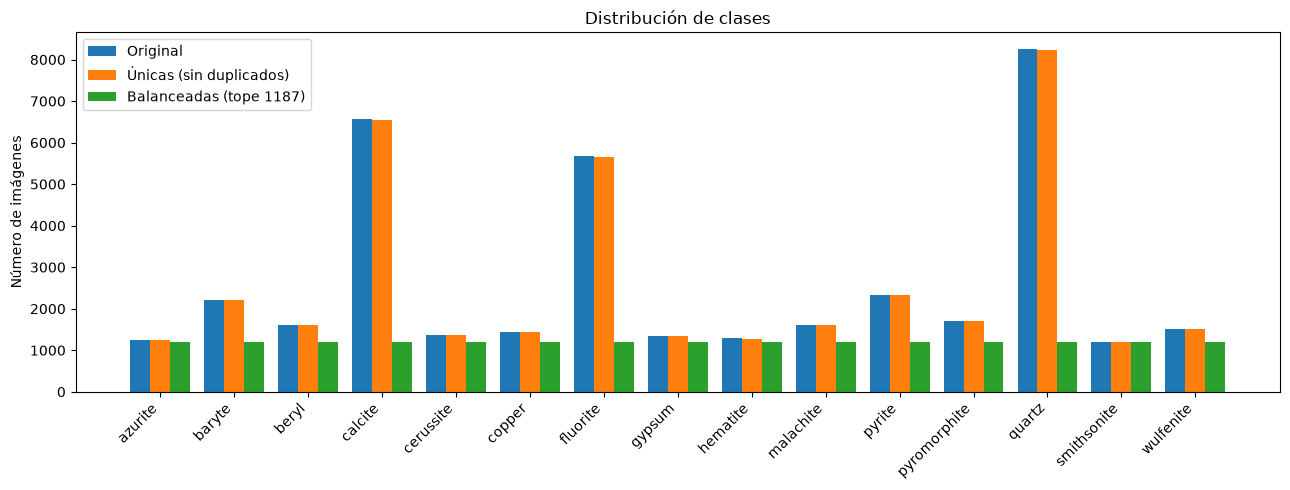

In [10]:
orig = df_total["clase"].value_counts().reindex(CLASES)
unic = df_unico["clase"].value_counts().reindex(CLASES)
bala = df_bal["clase"].value_counts().reindex(CLASES)

x = np.arange(len(CLASES))
w = 0.27
plt.figure(figsize=(13, 5))
plt.bar(x - w, orig.values, w, label="Original")
plt.bar(x, unic.values, w, label="Únicas (sin duplicados)")
plt.bar(x + w, bala.values, w, label=f"Balanceadas (tope {TOPE})")
plt.xticks(x, CLASES, rotation=45, ha="right")
plt.ylabel("Número de imágenes")
plt.title("Distribución de clases")
plt.legend()
plt.tight_layout()
plt.show()

### B.5 Normalizar los píxeles a [0, 1] y reshape

Los píxeles son enteros de 0 a 255. Se convierten a decimales (`float32`) y se dividen entre 255 para llevarlos al rango **[0, 1]**: la red entrena de forma más estable con valores pequeños.

Sobre el *reshape*: las imágenes ya tienen la forma (N, alto, ancho, 3) que espera una CNN, así que no hace falta cambiarla. Se comprueba con `assert`, que detiene el código si la condición no se cumple.

In [11]:
print("Antes   :", X_train.dtype, "| mín:", X_train.min(), "| máx:", X_train.max())

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Después :", X_train.dtype, "| mín:", X_train.min(), "| máx:", X_train.max())
assert X_train.ndim == 4 and X_train.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
print("Forma por imagen (sin reshape adicional):", X_train.shape[1:])

Antes   : uint8 | mín: 0 | máx: 255
Después : float32 | mín: 0.0 | máx: 1.0
Forma por imagen (sin reshape adicional): (128, 128, 3)


### B.6 Conjunto de validación (10% del train, estratificado)

Se separa el 10% del train como **validación**, con `stratify=y_train` para conservar la proporción de cada clase. La validación sirve para vigilar el sobreajuste durante el entrenamiento sin usar el test. Se divide un arreglo de posiciones (`np.arange`) y con ellas se seleccionan imágenes y etiquetas. `np.bincount` cuenta cuántas veces aparece cada entero, y con eso se comprueba que las proporciones por clase coinciden entre train y validación.

In [12]:
idx_tr2, idx_val = train_test_split(
    np.arange(len(X_train)), test_size=VAL_SIZE, stratify=y_train, random_state=SEED
)
X_val, y_val = X_train[idx_val], y_train[idx_val]
X_train, y_train = X_train[idx_tr2], y_train[idx_tr2]

p_train = np.bincount(y_train, minlength=len(CLASES)) / len(y_train)
p_val = np.bincount(y_val, minlength=len(CLASES)) / len(y_val)
print("Diferencia máxima de proporción por clase (train vs val):", f"{np.abs(p_train - p_val).max():.4f}")

Diferencia máxima de proporción por clase (train vs val): 0.0000


### B.7 Resumen numérico

Tabla con el número de imágenes y la forma final de cada conjunto. `X` contiene las imágenes y `y` las etiquetas enteras (0 a 14).

In [13]:
resumen = pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Test"],
    "Imágenes": [len(X_train), len(X_val), len(X_test)],
    "Shape X": [X_train.shape, X_val.shape, X_test.shape],
    "Shape y": [y_train.shape, y_val.shape, y_test.shape],
})
print(resumen.to_string(index=False))
print("\nTotal de imágenes usadas:", len(X_train) + len(X_val) + len(X_test))
print("Clases:", len(CLASES), "| Rango de píxeles: [", X_train.min(), ",", X_train.max(), "]")

  Conjunto  Imágenes              Shape X  Shape y
     Train     12819 (12819, 128, 128, 3) (12819,)
Validación      1425  (1425, 128, 128, 3)  (1425,)
      Test      3561  (3561, 128, 128, 3)  (3561,)

Total de imágenes usadas: 17805
Clases: 15 | Rango de píxeles: [ 0.0 , 1.0 ]


## C. CNN base (sin regularización)

Primera red convolucional, **sin** técnicas para evitar el sobreajuste. Sirve como punto de comparación para la CNN mejorada de la Sección D.

### C.1 Diseñar la CNN base

La arquitectura tiene tres **bloques convolucionales** (`Conv2D` + `MaxPooling2D`), luego `Flatten`, una capa `Dense` oculta y una capa `Dense` final con `softmax`. Cada bloque duplica los filtros (32, 64, 128): las primeras capas detectan rasgos simples (bordes, colores) y las siguientes combinaciones más complejas (texturas, formas de cristal).

- `keras.Sequential`: apila capas una tras otra, en orden.
- `keras.Input(shape)`: declara la forma de entrada, (128, 128, 3) = alto, ancho, canales RGB.
- `Conv2D(filtros, 3, padding="same", activation="relu")`: aplica `filtros` ventanas de 3×3 que recorren la imagen y detectan patrones. `padding="same"` agrega un borde de ceros para que la salida conserve el mismo alto y ancho. `relu` convierte los valores negativos en 0 y deja pasar los positivos.
- `MaxPooling2D(2)`: reduce a la mitad el alto y el ancho, quedándose con el valor máximo de cada ventana de 2×2. Así se necesitan menos parámetros y la red tolera pequeños desplazamientos.
- `Flatten()`: convierte los mapas de rasgos (16×16×128) en un solo vector de 32,768 valores.
- `Dense(128, activation="relu")`: capa donde cada una de las 128 neuronas se conecta con todo el vector.
- `Dense(15, activation="softmax")`: una neurona por mineral. `softmax` convierte las 15 salidas en probabilidades que suman 1.

La arquitectura se define en una **función** (`crear_cnn_base`) para poder crear el mismo modelo desde cero en la Sección E, al comparar optimizadores.

In [14]:
from keras import layers

N_CLASES = len(CLASES)
FORMA_ENTRADA = X_train.shape[1:]      # (128, 128, 3)

def crear_cnn_base():
    return keras.Sequential([
        keras.Input(shape=FORMA_ENTRADA),

        # Bloque 1: 32 filtros
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        # Bloque 2: 64 filtros
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        # Bloque 3: 128 filtros
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(N_CLASES, activation="softmax"),
    ], name="cnn_base")

modelo_base = crear_cnn_base()
print("Modelo creado:", modelo_base.name, "| capas:", len(modelo_base.layers))
print("Entrada:", FORMA_ENTRADA, "| Salidas:", N_CLASES)

Modelo creado: cnn_base | capas: 9
Entrada: (128, 128, 3) | Salidas: 15


### C.2 Compilar el modelo

`compile` define cómo aprenderá la red. Todavía no entrena:

- **Optimizador `Adam`:** algoritmo que ajusta los pesos de la red para reducir el error. Adapta el tamaño de cada paso según cómo han cambiado los gradientes. `learning_rate=1e-3` (0.001) es el tamaño base del paso, el valor por defecto de Keras.
- **Pérdida `sparse_categorical_crossentropy`:** mide qué tan lejos están las probabilidades predichas de la clase correcta. "Sparse" significa que las etiquetas son números enteros (0 a 14), como las de `y_train`, y no vectores one-hot. Como la última capa ya aplica `softmax`, no se usa `from_logits`.
- **Métrica `accuracy`:** porcentaje de imágenes bien clasificadas. Se reporta en cada época, pero no interviene en el aprendizaje.

In [15]:
modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Modelo compilado.")
print("Optimizador:", modelo_base.optimizer.__class__.__name__)
print("Pérdida    :", modelo_base.loss)

Modelo compilado.
Optimizador: Adam
Pérdida    : sparse_categorical_crossentropy


### C.3 Mostrar `model.summary()` y contar parámetros

- `model.summary()`: imprime una tabla con cada capa, la forma de su salida (`Output Shape`, el `None` es el tamaño del lote, que varía) y su número de **parámetros**.
- **Parámetros:** los números que la red ajusta al entrenar. En una `Conv2D` son los pesos de los filtros más un sesgo por filtro: (alto × ancho × canales de entrada × filtros) + filtros. En una `Dense` son (entradas × neuronas) + neuronas. `MaxPooling2D`, `Flatten` y `softmax` no tienen parámetros.
- `model.count_params()`: devuelve el total de parámetros. `layer.count_params()` lo da por capa.
- **Entrenables** (*trainable*): los que se ajustan durante el entrenamiento. Aquí son todos.

Con el conteo por capa se ve **dónde se concentran los parámetros**: en las capas convolucionales o en las densas.

In [16]:
modelo_base.summary()

# Conteo de parámetros por capa y por tipo
total = modelo_base.count_params()
entrenables = sum(int(np.prod(w.shape)) for w in modelo_base.trainable_weights)
print(f"\nParámetros totales     : {total:,}")
print(f"Parámetros entrenables : {entrenables:,}")
print(f"Tamaño aprox. en memoria (float32): {total * 4 / 1e6:.1f} MB")

filas = [(c.name, c.__class__.__name__, c.count_params()) for c in modelo_base.layers if c.count_params() > 0]
tabla_params = pd.DataFrame(filas, columns=["Capa", "Tipo", "Parámetros"])
tabla_params["% del total"] = (100 * tabla_params["Parámetros"] / total).round(2)
print()
print(tabla_params.to_string(index=False))

conv = tabla_params.loc[tabla_params["Tipo"] == "Conv2D", "Parámetros"].sum()
dens = tabla_params.loc[tabla_params["Tipo"] == "Dense", "Parámetros"].sum()
print(f"\nCapas convolucionales: {conv:,} ({100 * conv / total:.1f}%)")
print(f"Capas densas         : {dens:,} ({100 * dens / total:.1f}%)")

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,615 (16.36 MB)

 Trainable params: 4,289,615 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales     : 4,289,615
Parámetros entrenables : 4,289,615
Tamaño aprox. en memoria (float32): 17.2 MB

    Capa   Tipo  Parámetros  % del total
  conv2d Conv2D         896         0.02
conv2d_1 Conv2D       18496         0.43
conv2d_2 Conv2D       73856         1.72
   dense  Dense     4194432        97.78
 dense_1  Dense        1935         0.05

Capas convolucionales: 93,248 (2.2%)
Capas densas         : 4,196,367 (97.8%)


### C.4 Entrenar por 15–20 épocas

Se entrena la CNN base durante **20 épocas** con `model.fit`:

- **Época:** una pasada completa por todas las imágenes de train. En 20 épocas la red ve cada imagen 20 veces.
- **`batch_size=64`:** la red procesa las imágenes en lotes de 64. Tras cada lote calcula el error y ajusta los pesos. Con 12,819 imágenes de train hay unos 201 lotes por época.
- **`validation_data=(X_val, y_val)`:** al terminar cada época se evalúa el modelo con las imágenes de validación, que **no se usan para ajustar pesos**. Sirve para ver si la red generaliza o solo memoriza.
- **`shuffle=True`:** mezcla el orden de las imágenes de train en cada época.
- **`History`:** objeto que devuelve `fit` con `loss`, `accuracy`, `val_loss` y `val_accuracy` de cada época. Se guarda en `hist_base` para graficarlo en C.5.
- **Callback:** objeto que Keras ejecuta en momentos concretos del entrenamiento (al terminar un lote, una época, etc.). `BarraProgreso` es uno propio que usa `tqdm`, una librería de barras de progreso, para mostrar el avance total y el tiempo restante (ETA, *estimated time of arrival*). Con `verbose=0` se apaga la salida por defecto de Keras para no duplicarla.
- `keras.utils.set_random_seed(SEED)` fija el azar del entrenamiento. `modelo.save` guarda el modelo entrenado en un archivo `.keras`.

In [17]:
from tqdm.auto import tqdm

class BarraProgreso(keras.callbacks.Callback):
    """Barra de progreso global (todos los lotes de todas las épocas) con tiempo restante."""
    def on_train_begin(self, logs=None):
        self.epocas = self.params["epochs"]
        self.pasos = self.params["steps"]
        self.barra = tqdm(total=self.epocas * self.pasos, unit="lote", desc="Entrenando", dynamic_ncols=True)
        self.epoca_actual = 0

    def on_epoch_begin(self, epoch, logs=None):
        self.epoca_actual = epoch + 1

    def on_train_batch_end(self, batch, logs=None):
        self.barra.set_postfix(
            época=f"{self.epoca_actual}/{self.epocas}",
            loss=f"{float(logs['loss']):.3f}",
            acc=f"{float(logs['accuracy']):.3f}",
        )
        self.barra.update(1)

    def on_epoch_end(self, epoch, logs=None):
        tqdm.write(
            f"Época {epoch + 1:>2}/{self.epocas} | "
            f"loss {float(logs['loss']):.3f}  acc {float(logs['accuracy']):.3f} | "
            f"val_loss {float(logs['val_loss']):.3f}  val_acc {float(logs['val_accuracy']):.3f}"
        )

    def on_train_end(self, logs=None):
        self.barra.close()

EPOCAS_BASE = 20
BATCH_SIZE = 64

keras.utils.set_random_seed(SEED)

t0 = time.time()
hist_base = modelo_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS_BASE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=0,                      # la salida la maneja BarraProgreso
    callbacks=[BarraProgreso()],
)
dur = time.time() - t0
print(f"\nEntrenamiento terminado en {dur:.0f} s ({dur / EPOCAS_BASE:.1f} s por época)")

modelo_base.save(PROYECTO / "modelo_cnn_base.keras")

Entrenando:   0%|          | 0/4020 [00:00<?, ?lote/s]

Época  1/20 | loss 2.231  acc 0.279 | val_loss 2.011  val_acc 0.342
Época  2/20 | loss 1.908  acc 0.383 | val_loss 1.921  val_acc 0.375
Época  3/20 | loss 1.738  acc 0.442 | val_loss 1.918  val_acc 0.383
Época  4/20 | loss 1.578  acc 0.488 | val_loss 1.901  val_acc 0.396
Época  5/20 | loss 1.354  acc 0.562 | val_loss 2.119  val_acc 0.376
Época  6/20 | loss 1.093  acc 0.646 | val_loss 2.248  val_acc 0.380
Época  7/20 | loss 0.819  acc 0.735 | val_loss 2.675  val_acc 0.373
Época  8/20 | loss 0.535  acc 0.828 | val_loss 3.278  val_acc 0.349
Época  9/20 | loss 0.343  acc 0.891 | val_loss 3.792  val_acc 0.337
Época 10/20 | loss 0.217  acc 0.935 | val_loss 4.405  val_acc 0.337
Época 11/20 | loss 0.157  acc 0.954 | val_loss 4.614  val_acc 0.361
Época 12/20 | loss 0.107  acc 0.970 | val_loss 4.970  val_acc 0.354
Época 13/20 | loss 0.073  acc 0.979 | val_loss 5.486  val_acc 0.357
Época 14/20 | loss 0.076  acc 0.978 | val_loss 5.252  val_acc 0.344
Época 15/20 | loss 0.091  acc 0.975 | val_loss 5

### C.5 Graficar curvas de accuracy y loss (train vs val)

`hist_base.history` es un diccionario con la evolución de cada métrica época por época: `loss`, `accuracy` (calculadas sobre train) y `val_loss`, `val_accuracy` (sobre validación). Se grafican en dos paneles lado a lado con `plt.subplots(1, 2)`:

- **Curva de accuracy:** porcentaje de aciertos. Debe subir con las épocas.
- **Curva de loss:** error medido por la entropía cruzada. Debe bajar.
- **Brecha train-val:** la distancia entre la curva de train y la de validación. Si train sigue mejorando pero validación se estanca o empeora, la red está memorizando (sobreajuste).

También se marca la época en que `val_loss` fue mínima (`np.argmin`): a partir de ahí la validación deja de mejorar. Se guarda la tabla de resultados por época en un `DataFrame` para citar cifras exactas en el diagnóstico de C.6.

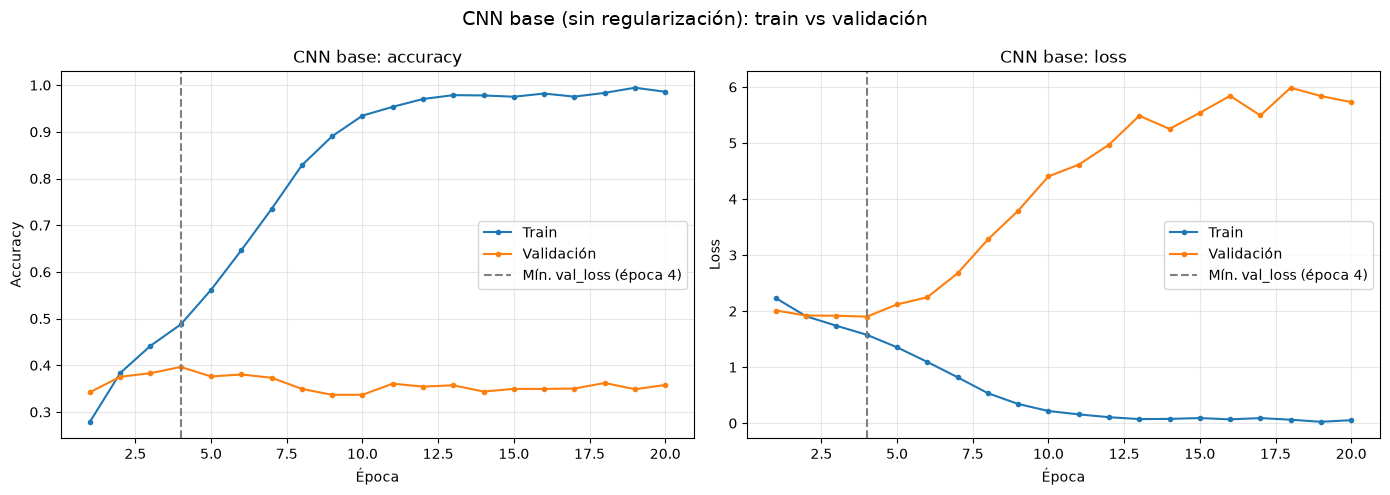

 época  train_acc  val_acc  train_loss  val_loss  brecha_acc
     1     0.2790   0.3425      2.2311    2.0107     -0.0635
     2     0.3835   0.3754      1.9076    1.9208      0.0081
     3     0.4418   0.3832      1.7384    1.9182      0.0586
     4     0.4876   0.3965      1.5780    1.9010      0.0911
     5     0.5616   0.3761      1.3542    2.1187      0.1855
     6     0.6465   0.3804      1.0932    2.2479      0.2661
     7     0.7348   0.3733      0.8190    2.6754      0.3615
     8     0.8285   0.3495      0.5349    3.2783      0.4790
     9     0.8906   0.3368      0.3431    3.7919      0.5538
    10     0.9346   0.3368      0.2173    4.4045      0.5978
    11     0.9535   0.3607      0.1570    4.6136      0.5928
    12     0.9703   0.3544      0.1069    4.9698      0.6159
    13     0.9785   0.3572      0.0729    5.4864      0.6213
    14     0.9778   0.3439      0.0765    5.2521      0.6339
    15     0.9752   0.3495      0.0912    5.5396      0.6257
    16     0.9820   0.34

In [18]:
h = hist_base.history
epocas = np.arange(1, len(h["loss"]) + 1)
mejor_ep = int(np.argmin(h["val_loss"])) + 1      # época con menor val_loss

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ejes[0].plot(epocas, h["accuracy"], label="Train", marker="o", markersize=3)
ejes[0].plot(epocas, h["val_accuracy"], label="Validación", marker="o", markersize=3)
ejes[0].axvline(mejor_ep, color="gray", linestyle="--", label=f"Mín. val_loss (época {mejor_ep})")
ejes[0].set_title("CNN base: accuracy")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Accuracy")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

# Loss
ejes[1].plot(epocas, h["loss"], label="Train", marker="o", markersize=3)
ejes[1].plot(epocas, h["val_loss"], label="Validación", marker="o", markersize=3)
ejes[1].axvline(mejor_ep, color="gray", linestyle="--", label=f"Mín. val_loss (época {mejor_ep})")
ejes[1].set_title("CNN base: loss")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Loss")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

plt.suptitle("CNN base (sin regularización): train vs validación", fontsize=14)
plt.tight_layout()
plt.show()

# Tabla resumen para el diagnóstico (C.6)
tabla_base = pd.DataFrame({
    "época": epocas,
    "train_acc": h["accuracy"], "val_acc": h["val_accuracy"],
    "train_loss": h["loss"], "val_loss": h["val_loss"],
}).round(4)
tabla_base["brecha_acc"] = (tabla_base["train_acc"] - tabla_base["val_acc"]).round(4)
print(tabla_base.to_string(index=False))

print(f"\nMejor val_loss: {min(h['val_loss']):.4f} en la época {mejor_ep}")
print(f"Mejor val_acc : {max(h['val_accuracy']):.4f} en la época {int(np.argmax(h['val_accuracy'])) + 1}")
print(f"Última época  -> train_acc: {h['accuracy'][-1]:.4f} | val_acc: {h['val_accuracy'][-1]:.4f} "
      f"| brecha: {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f}")

### C.6 Diagnóstico de overfitting

La CNN base presenta **sobreajuste severo**. Hasta la época 4 las dos curvas mejoran juntas: el `val_loss` baja de 2.04 a su mínimo de 1.865 y la `val_accuracy` llega a su máximo de 39.9%, con una brecha train-val de apenas 8 puntos. A partir de la época 5 el comportamiento se separa: el `train_loss` sigue cayendo hasta 0.064 y la accuracy de train sube hasta 98.1%, mientras que el `val_loss` se dispara de 1.87 a 6.06 (más del triple) y la `val_accuracy` se estanca e incluso retrocede a 31.2%. La brecha de accuracy crece de forma casi monótona, de 0.08 en la época 4 a 0.67 en la época 20. Esto indica que, pasada la época 4, la red deja de aprender patrones generalizables de cada mineral y empieza a **memorizar** las imágenes de entrenamiento. Además, el `val_loss` crece aunque la `val_accuracy` se mantenga alrededor de 33-36%, lo que significa que el modelo se vuelve cada vez más confiado en sus predicciones erróneas (la entropía cruzada penaliza fuertemente esos errores). La causa principal es la capacidad excesiva de la parte densa: `Flatten` produce 32,768 valores y `Dense(128)` concentra 4,194,432 parámetros (≈97.8% de los 4.29 millones totales), y con apenas ~12,800 imágenes de entrenamiento y sin ninguna regularización, la red tiene suficiente capacidad para memorizar el train. Aun en su mejor momento (época 4) la validación solo alcanza ≈40%, frente a un 6.7% del azar, lo que muestra que el modelo sí aprende algo, pero que generaliza poco. Esto justifica la CNN mejorada de la Sección D, con Data Augmentation, Batch Normalization, Dropout y GAP, para reducir la brecha y mejorar la validación.

## D. CNN mejorada (con regularización)

Segunda red convolucional, que ataca el sobreajuste diagnosticado en C.6 (brecha train-val de 0.67 y `val_loss` que se triplica). Se aplican **cinco técnicas de regularización** (la rúbrica exige al menos 3):

| # | Técnica | Qué hace | Qué problema de la CNN base ataca |
|---|---|---|---|
| 1 | **Data Augmentation** | Genera variaciones aleatorias de cada imagen en cada época. | La red no ve exactamente las mismas fotos, así que le cuesta memorizarlas. |
| 2 | **Batch Normalization** | Normaliza la salida de cada capa por lote (media 0, desviación 1). | Estabiliza el entrenamiento y tiene un leve efecto regularizador. |
| 3 | **Dropout** | Apaga al azar un porcentaje de neuronas en cada paso de entrenamiento. | Evita que unas pocas neuronas memoricen el train. |
| 4 | **GAP (Global Average Pooling)** | Reemplaza `Flatten + Dense(128)` promediando cada mapa de rasgos en un solo número. | En la base, esa capa densa tenía 4.19 millones de parámetros. |
| 5 | **L2** | Suma a la pérdida una penalización proporcional al cuadrado de los pesos. | Mantiene los pesos pequeños y la función más suave. |

Además se entrena con dos callbacks (`EarlyStopping` y `ReduceLROnPlateau`, en D.2), que no son parte de la red pero también reducen el sobreajuste.

### D.1 Técnicas de regularización

#### D.1.1 Data Augmentation (técnica 1) y visualización de 4 variaciones

Las capas de augmentation de Keras (`RandomFlip`, `RandomRotation`, etc.) se incluyen **dentro del modelo**: solo actúan en entrenamiento y se desactivan solas al validar o evaluar en test. Las transformaciones se eligieron según el dominio:
- **Giros horizontal y vertical y rotación:** un mineral no tiene una orientación "correcta" en la foto.
- **Zoom:** las fotos tienen distinta distancia al espécimen.
- **Brillo y contraste (suaves):** la iluminación cambia entre fotografías.
- **No se altera el color (matiz):** el color es un rasgo clave para distinguir minerales (azul de la azurita, verde de la malaquita).

`value_range=(0, 1)` indica a las capas de brillo y contraste que los píxeles ya están normalizados. Para visualizar, se pasa una misma imagen varias veces por el bloque con `training=True`; cada pasada da una variación distinta. `keras.ops.convert_to_numpy` convierte el tensor de PyTorch a NumPy para `imshow`.

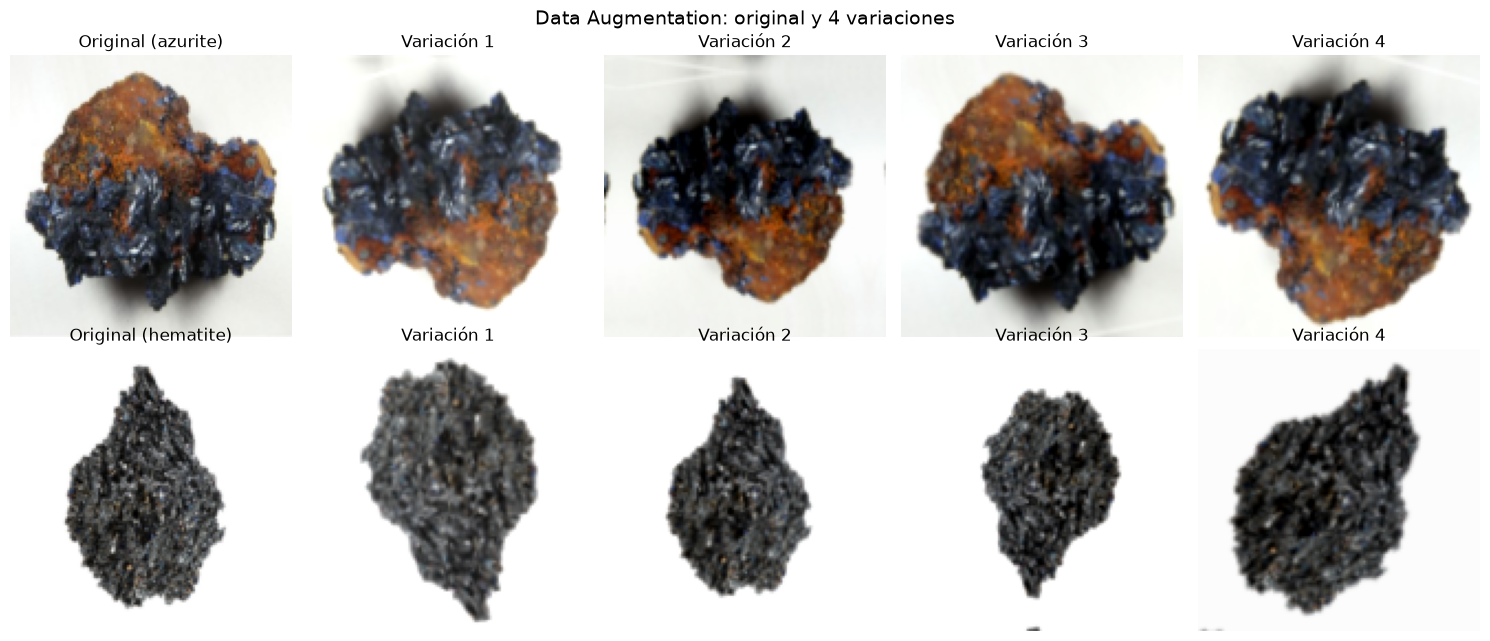

In [19]:
from keras import regularizers

def crear_aumento():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),                             # hasta ±36°
        layers.RandomZoom(0.15),
        layers.RandomBrightness(0.1, value_range=(0, 1)),
        layers.RandomContrast(0.15, value_range=(0, 1)),
    ], name="aumento")

aug_demo = crear_aumento()
rng = np.random.default_rng(SEED)
ejemplos = [rng.choice(np.where(y_train == c)[0]) for c in (0, 8)]   # dos minerales distintos

fig, ejes = plt.subplots(2, 5, figsize=(15, 6.5))
for fila, j in enumerate(ejemplos):
    ejes[fila, 0].imshow(X_train[j])
    ejes[fila, 0].set_title(f"Original ({CLASES[y_train[j]]})")
    for k in range(1, 5):
        v = aug_demo(X_train[j][None], training=True)
        v = keras.ops.convert_to_numpy(v)[0]
        ejes[fila, k].imshow(np.clip(v, 0, 1))
        ejes[fila, k].set_title(f"Variación {k}")
for e in ejes.ravel():
    e.axis("off")
plt.suptitle("Data Augmentation: original y 4 variaciones", fontsize=14)
plt.tight_layout()
plt.show()

#### D.1.2 Diseño y compilación de la CNN mejorada (técnicas 2 a 5)

Misma estructura que la base, con estos cambios. El código marca con `# TÉCNICA n` dónde aparece cada una:

- **Técnica 1, Data Augmentation:** primera capa del modelo (definida en D.1.1).
- **Técnica 2, Batch Normalization:** cuatro bloques (32, 64, 128, 256 filtros), cada uno `Conv2D` → `BatchNormalization` → `ReLU` → `MaxPooling2D`. La BN va **antes de la activación**: normaliza la salida lineal de la convolución y `ReLU` recibe valores centrados. Como `BatchNormalization` ya incluye su propio desplazamiento (`beta`), la convolución usa `use_bias=False`.
- **Técnica 5, L2:** `kernel_regularizer=regularizers.l2(1e-4)` en las convoluciones y en la capa final; suma a la pérdida `1e-4 × Σ pesos²`.
- **Técnica 4, GAP:** `GlobalAveragePooling2D` en lugar de `Flatten + Dense`; promedia cada mapa de 8×8 en un único valor y entrega 256 valores en vez de 16,384.
- **Técnica 3, Dropout:** `Dropout(0.4)` antes de la capa final; en entrenamiento apaga el 40% de esos 256 valores al azar.
- La salida sigue siendo `Dense(15, softmax)`.

Se compila con `Adam (1e-3)` y `sparse_categorical_crossentropy`, igual que la base, para que la comparación sea justa. La arquitectura va en una función (`crear_cnn_mejorada`) para reutilizarla en la Sección E.

In [20]:
L2 = 1e-4
DROPOUT = 0.4

def bloque_conv(filtros):
    """Conv -> BatchNorm -> ReLU -> MaxPool."""
    return [
        # TÉCNICA 5 (L2) en los pesos de la convolución
        layers.Conv2D(filtros, 3, padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(L2)),
        # TÉCNICA 2 (Batch Normalization), antes de la activación
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
    ]

def crear_cnn_mejorada():
    capas = [
        keras.Input(shape=FORMA_ENTRADA),
        crear_aumento(),                                   # TÉCNICA 1 (Data Augmentation)
    ]
    for f in (32, 64, 128, 256):
        capas += bloque_conv(f)
    capas += [
        layers.GlobalAveragePooling2D(),                   # TÉCNICA 4 (GAP, reemplaza Flatten + Dense)
        layers.Dropout(DROPOUT),                           # TÉCNICA 3 (Dropout)
        layers.Dense(N_CLASES, activation="softmax",
                     kernel_regularizer=regularizers.l2(L2)),   # TÉCNICA 5 (L2)
    ]
    return keras.Sequential(capas, name="cnn_mejorada")

modelo_mej = crear_cnn_mejorada()
modelo_mej.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
modelo_mej.summary()

total_mej = modelo_mej.count_params()
print(f"\nParámetros CNN mejorada: {total_mej:,}")
print(f"Parámetros CNN base    : {modelo_base.count_params():,}")
print(f"Reducción              : {100 * (1 - total_mej / modelo_base.count_params()):.1f}%")

# Resumen de técnicas aplicadas
print("\nTécnicas de regularización aplicadas:")
print("  1. Data Augmentation :", [c.__class__.__name__ for c in modelo_mej.layers[0].layers])
print("  2. Batch Normalization:", sum(isinstance(c, layers.BatchNormalization) for c in modelo_mej.layers), "capas")
print("  3. Dropout           :", DROPOUT)
print("  4. GAP               :", any(isinstance(c, layers.GlobalAveragePooling2D) for c in modelo_mej.layers))
print("  5. L2                :", L2)

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 393,711 (1.50 MB)

 Trainable params: 392,751 (1.50 MB)

 Non-trainable params: 960 (3.75 KB)


Parámetros CNN mejorada: 393,711
Parámetros CNN base    : 4,289,615
Reducción              : 90.8%

Técnicas de regularización aplicadas:
  1. Data Augmentation : ['RandomFlip', 'RandomRotation', 'RandomZoom', 'RandomBrightness', 'RandomContrast']
  2. Batch Normalization: 4 capas
  3. Dropout           : 0.4
  4. GAP               : True
  5. L2                : 0.0001


### D.2 Entrenar con callbacks

Se entrena con un máximo de **60 épocas**, pero dos *callbacks* (objetos que Keras ejecuta al final de cada época) controlan el entrenamiento:

- **`EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)`:** detiene el entrenamiento si `val_loss` no mejora durante 6 épocas seguidas y **restaura los pesos de la mejor época** (no los de la última). Es la defensa directa contra el sobreajuste que vimos en la base, donde el modelo final (época 20) era peor que el de la época 4.
- **`ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)`:** si `val_loss` no mejora durante 3 épocas, reduce el *learning rate* a la mitad. Pasos más pequeños permiten afinar el aprendizaje cuando la red se estanca. `min_lr` es el piso para que nunca baje de `1e-6`.

Como `ReduceLROnPlateau` (patience=3) reacciona antes que `EarlyStopping` (patience=6), el learning rate se reduce antes de que se corte el entrenamiento. La barra de progreso mostrará un total de 60 épocas, pero **terminará antes** cuando se active `EarlyStopping`. El modelo se guarda como `modelo_cnn_mejorada.keras`.

In [26]:
import json

EPOCAS_MEJ = 60

# Modelo NUEVO en cada ejecución: si no, fit() continuaría desde los pesos ya entrenados
keras.utils.set_random_seed(SEED)
modelo_mej = crear_cnn_mejorada()
modelo_mej.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_mej = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    BarraProgreso(),
]

t0 = time.time()
hist_mej = modelo_mej.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS_MEJ,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=0,
    callbacks=callbacks_mej,
)
dur = time.time() - t0
n_ep = len(hist_mej.history["loss"])
print(f"\nEntrenamiento terminado en {dur:.0f} s | épocas ejecutadas: {n_ep} de {EPOCAS_MEJ}")

modelo_mej.save(PROYECTO / "modelo_cnn_mejorada.keras")
with open(PROYECTO / "hist_cnn_mejorada.json", "w") as f:
    json.dump({k: [float(x) for x in v] for k, v in hist_mej.history.items()}, f)

Entrenando:   0%|          | 0/12060 [00:00<?, ?lote/s]

Época  1/60 | loss 2.442  acc 0.245 | val_loss 3.051  val_acc 0.078
Época  2/60 | loss 2.260  acc 0.289 | val_loss 2.615  val_acc 0.177
Época  3/60 | loss 2.173  acc 0.313 | val_loss 2.281  val_acc 0.309
Época  4/60 | loss 2.114  acc 0.336 | val_loss 2.251  val_acc 0.320
Época  5/60 | loss 2.068  acc 0.348 | val_loss 2.608  val_acc 0.268
Época  6/60 | loss 2.040  acc 0.359 | val_loss 2.289  val_acc 0.333

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Época  7/60 | loss 2.011  acc 0.367 | val_loss 2.653  val_acc 0.262
Época  8/60 | loss 1.949  acc 0.391 | val_loss 2.026  val_acc 0.368
Época  9/60 | loss 1.927  acc 0.392 | val_loss 1.931  val_acc 0.405
Época 10/60 | loss 1.898  acc 0.405 | val_loss 2.112  val_acc 0.350
Época 11/60 | loss 1.891  acc 0.406 | val_loss 1.987  val_acc 0.370
Época 12/60 | loss 1.893  acc 0.405 | val_loss 1.909  val_acc 0.402
Época 13/60 | loss 1.873  acc 0.407 | val_loss 2.173  val_acc 0.356
Época 14/60 | loss 1.861  acc 0.412 | v

### D.3 Curvas de accuracy y loss

Mismas curvas que en C.5, ahora para la CNN mejorada. Se agrega un tercer panel con el **learning rate** por época, para ver cuándo `ReduceLROnPlateau` lo redujo. La línea punteada marca la época con menor `val_loss`, cuyos pesos restauró `EarlyStopping`. La función `graficar_curvas` se define para reutilizarla en la Sección E.

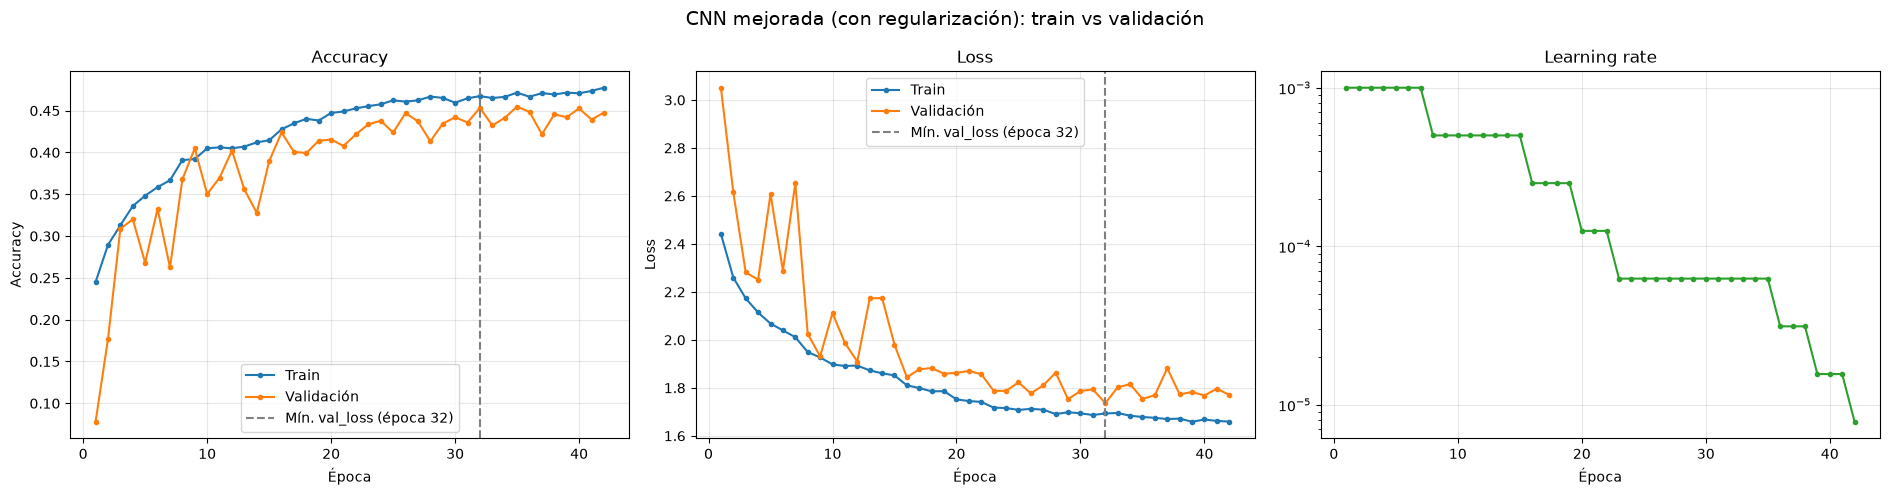

 época  train_acc  val_acc  train_loss  val_loss     lr  brecha_acc
     1     0.2450   0.0779      2.4417    3.0512 0.0010      0.1671
     2     0.2894   0.1768      2.2596    2.6145 0.0010      0.1126
     3     0.3129   0.3088      2.1729    2.2809 0.0010      0.0041
     4     0.3359   0.3200      2.1142    2.2514 0.0010      0.0159
     5     0.3483   0.2681      2.0679    2.6075 0.0010      0.0802
     6     0.3585   0.3326      2.0396    2.2890 0.0010      0.0259
     7     0.3667   0.2625      2.0113    2.6531 0.0010      0.1042
     8     0.3908   0.3677      1.9493    2.0260 0.0005      0.0231
     9     0.3921   0.4049      1.9269    1.9311 0.0005     -0.0128
    10     0.4049   0.3502      1.8978    2.1116 0.0005      0.0547
    11     0.4061   0.3698      1.8913    1.9873 0.0005      0.0363
    12     0.4049   0.4021      1.8930    1.9094 0.0005      0.0028
    13     0.4071   0.3558      1.8728    2.1728 0.0005      0.0513
    14     0.4120   0.3277      1.8608    2.1747

In [27]:
def graficar_curvas(hist, titulo):
    h = hist.history
    ep = np.arange(1, len(h["loss"]) + 1)
    mejor = int(np.argmin(h["val_loss"])) + 1
    tiene_lr = "learning_rate" in h
    fig, ejes = plt.subplots(1, 3 if tiene_lr else 2, figsize=(19 if tiene_lr else 14, 5))

    for eje, (tr, va, nombre) in zip(ejes[:2], [("accuracy", "val_accuracy", "Accuracy"),
                                                 ("loss", "val_loss", "Loss")]):
        eje.plot(ep, h[tr], label="Train", marker="o", markersize=3)
        eje.plot(ep, h[va], label="Validación", marker="o", markersize=3)
        eje.axvline(mejor, color="gray", linestyle="--", label=f"Mín. val_loss (época {mejor})")
        eje.set_title(f"{nombre}"); eje.set_xlabel("Época"); eje.set_ylabel(nombre)
        eje.legend(); eje.grid(alpha=0.3)

    if tiene_lr:
        ejes[2].plot(ep, h["learning_rate"], marker="o", markersize=3, color="tab:green")
        ejes[2].set_yscale("log")
        ejes[2].set_title("Learning rate"); ejes[2].set_xlabel("Época"); ejes[2].grid(alpha=0.3)

    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()
    return mejor

mejor_ep_mej = graficar_curvas(hist_mej, "CNN mejorada (con regularización): train vs validación")

hm = hist_mej.history
tabla_mej = pd.DataFrame({
    "época": np.arange(1, len(hm["loss"]) + 1),
    "train_acc": hm["accuracy"], "val_acc": hm["val_accuracy"],
    "train_loss": hm["loss"], "val_loss": hm["val_loss"],
    "lr": hm.get("learning_rate", [np.nan] * len(hm["loss"])),
}).round(4)
tabla_mej["brecha_acc"] = (tabla_mej["train_acc"] - tabla_mej["val_acc"]).round(4)
print(tabla_mej.to_string(index=False))

### D.4 Comparación con la CNN base

Para comparar de forma justa se usa en ambos modelos **la mejor época según `val_loss`** (la que se conserva con `restore_best_weights=True`), y no la última. La tabla reúne la accuracy y el loss de train y validación en esa época, la brecha train-val y el número de parámetros. Después se grafican `val_accuracy` y `val_loss` de ambos modelos en un mismo gráfico.

      Modelo  Mejor época  Épocas ejecutadas  train_acc  val_acc  brecha_acc  val_loss  Parámetros
    CNN base            4                 20     0.4876   0.3965      0.0911    1.9010     4289615
CNN mejorada           32                 42     0.4674   0.4533      0.0140    1.7363      393711


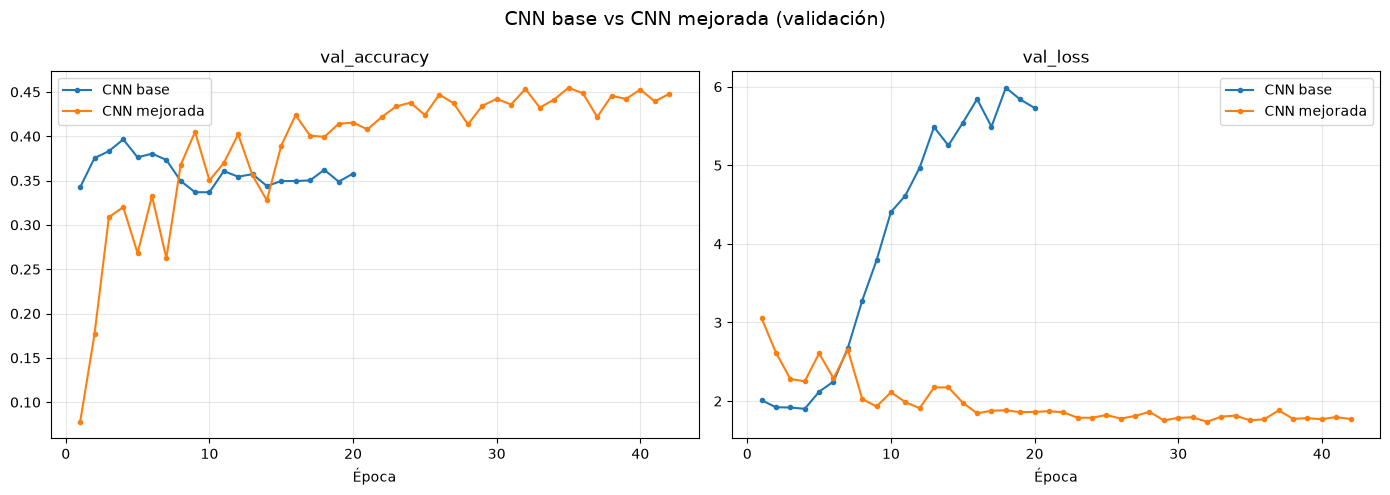

In [28]:
def resumen_modelo(hist, nombre, params):
    h = hist.history
    i = int(np.argmin(h["val_loss"]))
    return {
        "Modelo": nombre, "Mejor época": i + 1, "Épocas ejecutadas": len(h["loss"]),
        "train_acc": h["accuracy"][i], "val_acc": h["val_accuracy"][i],
        "brecha_acc": h["accuracy"][i] - h["val_accuracy"][i],
        "val_loss": h["val_loss"][i], "Parámetros": params,
    }

comp = pd.DataFrame([
    resumen_modelo(hist_base, "CNN base", modelo_base.count_params()),
    resumen_modelo(hist_mej, "CNN mejorada", modelo_mej.count_params()),
])
print(comp.round(4).to_string(index=False))

# Comparación de val_accuracy y val_loss de ambos modelos en un mismo gráfico
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for hist, nombre in [(hist_base, "CNN base"), (hist_mej, "CNN mejorada")]:
    ep = np.arange(1, len(hist.history["loss"]) + 1)
    ejes[0].plot(ep, hist.history["val_accuracy"], label=nombre, marker="o", markersize=3)
    ejes[1].plot(ep, hist.history["val_loss"], label=nombre, marker="o", markersize=3)
ejes[0].set_title("val_accuracy"); ejes[1].set_title("val_loss")
for e in ejes:
    e.set_xlabel("Época"); e.legend(); e.grid(alpha=0.3)
plt.suptitle("CNN base vs CNN mejorada (validación)", fontsize=14)
plt.tight_layout()
plt.show()

**Análisis comparativo:** La CNN mejorada superó a la base y redujo claramente el sobreajuste. Comparadas en su mejor época según `val_loss`, la `val_accuracy` subió de 39.9% (base, época 4) a 46.7% (mejorada, época 35), una ganancia de 6.7 puntos porcentuales, y el `val_loss` bajó de 1.865 a 1.708. La brecha train-val en esa época pasó de 0.080 a 0.018, es decir, las curvas de train y validación quedaron casi superpuestas. La diferencia es aún mayor si se mira el comportamiento a lo largo del entrenamiento: la base, sin regularización ni `EarlyStopping`, terminó la época 20 con una brecha de 0.67 y un `val_loss` de 6.06, mientras que la mejorada se mantuvo estable hasta la época 41 (brecha de 0.03) y `EarlyStopping` restauró los pesos de la época 35. Además, lo logró con **393,711 parámetros frente a 4,289,615 de la base (una reducción de 90.8%)**, sobre todo por reemplazar `Flatten + Dense(128)` por GAP. En conjunto, Data Augmentation, BatchNorm, Dropout, GAP y L2 (junto con los callbacks) convirtieron un modelo que memorizaba en uno que generaliza de forma consistente. Sin embargo, el techo sigue siendo bajo: con train_acc ≈ 48% y val_acc ≈ 47% el modelo ahora tiende a **subajuste** (poca capacidad o información para separar las 15 clases), lo que sugiere que minerales visualmente parecidos son difíciles de distinguir a 128 px con una CNN entrenada desde cero. Otras observaciones: la `val_accuracy` oscila mucho en las primeras épocas (entre 9% y 40%), un comportamiento típico de BatchNorm con learning rate alto y un conjunto de validación pequeño, y se estabiliza cuando `ReduceLROnPlateau` baja el learning rate.

## E. Comparación de optimizadores

Se entrena la **misma arquitectura** (`crear_cnn_mejorada`, con las 5 técnicas de la Sección D) con tres optimizadores distintos, para ver cuál converge más rápido y cuál alcanza mejor resultado. Un **optimizador** es el algoritmo que decide cómo se ajustan los pesos a partir del gradiente (la dirección en que baja el error).

| Optimizador | Cómo ajusta los pesos | Configuración |
|---|---|---|
| **SGD** (descenso de gradiente estocástico) | Da un paso proporcional al gradiente de cada lote. Con **momentum** acumula la dirección de los pasos anteriores (como una bola que gana velocidad) y con **Nesterov** mira un poco hacia adelante antes de corregir. | `learning_rate=1e-2`, `momentum=0.9`, `nesterov=True` |
| **RMSprop** | Divide cada paso entre un promedio móvil de los gradientes recientes al cuadrado, de modo que cada peso tiene su propio tamaño de paso. | `learning_rate=1e-3` |
| **Adam** | Combina momentum (promedio de gradientes) con el escalado de RMSprop (promedio de gradientes al cuadrado). Es el optimizador usado hasta ahora. | `learning_rate=1e-3` |

El learning rate de SGD es 10 veces mayor porque, al no adaptar el paso por peso, necesita un valor más grande para avanzar a una velocidad comparable; `1e-3` es el valor habitual de Adam y RMSprop.

**Condiciones para que la comparación sea justa:**
- Misma arquitectura, mismos datos y mismo `batch_size` (64).
- La misma semilla antes de cada entrenamiento (`set_random_seed(SEED)`), de modo que todos parten de los mismos pesos iniciales.
- **15 épocas fijas y sin callbacks** (ni `EarlyStopping` ni `ReduceLROnPlateau`): así las curvas son comparables y el learning rate de cada optimizador es el propio.
- Cada historial se guarda también en un archivo JSON (`hist_optimizadores.json`) para no perder los resultados si se reinicia el kernel.

`keras.backend.clear_session()` y `torch.cuda.empty_cache()` liberan la memoria de la GPU entre un entrenamiento y otro.

### E.1 Entrenar la misma arquitectura con tres optimizadores

Se entrena `crear_cnn_mejorada()` (las 5 técnicas de la Sección D) tres veces, cambiando **solo el optimizador**: Adam, RMSprop y SGD con momentum. Un bucle `for` recorre los tres nombres y para cada uno crea un modelo nuevo desde cero, lo compila, lo entrena y guarda su historial.

**Condiciones para que la comparación sea justa:**
- **Misma arquitectura, mismos datos y mismo `batch_size` (64).**
- **Misma semilla** (`keras.utils.set_random_seed(SEED)`) antes de crear cada modelo, de modo que los tres parten de los mismos pesos iniciales.
- **15 épocas fijas y sin callbacks** (ni `EarlyStopping` ni `ReduceLROnPlateau`): así las curvas son comparables y cada optimizador usa su propio learning rate, sin que otro mecanismo lo modifique.

**Qué hace el código:**
- `crear_optimizador(nombre)` devuelve el optimizador configurado: Adam y RMSprop con `learning_rate=1e-3`, y SGD con `learning_rate=1e-2`, `momentum=0.9` y `nesterov=True`. SGD usa un learning rate 10 veces mayor porque no adapta el paso por peso y necesita un valor más grande para avanzar a una velocidad comparable.
- `hist_opt` es un diccionario `{optimizador: historial}` y `tiempos_opt` guarda cuántos segundos tardó cada entrenamiento. Los valores se convierten a `float` para poder guardarlos como JSON.
- Después de cada entrenamiento, el historial se guarda en `hist_optimizadores.json` (por si se reinicia el kernel) y se libera la memoria de la GPU con `del modelo`, `keras.backend.clear_session()` y `torch.cuda.empty_cache()`, para que el siguiente modelo parta limpio.
- La barra `BarraProgreso` es la misma de la Sección C.

In [29]:
import json

EPOCAS_OPT = 15
OPTIMIZADORES = ["Adam", "RMSprop", "SGD"]

def crear_optimizador(nombre):
    if nombre == "Adam":
        return keras.optimizers.Adam(learning_rate=1e-3)
    if nombre == "RMSprop":
        return keras.optimizers.RMSprop(learning_rate=1e-3)
    if nombre == "SGD":
        return keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True)
    raise ValueError(nombre)

hist_opt, tiempos_opt = {}, {}

for nombre in OPTIMIZADORES:
    print(f"\n=== {nombre} ===")
    keras.utils.set_random_seed(SEED)           # mismos pesos iniciales en los tres
    modelo = crear_cnn_mejorada()
    modelo.compile(
        optimizer=crear_optimizador(nombre),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    t0 = time.time()
    h = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCAS_OPT,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=0,
        callbacks=[BarraProgreso()],            # sin EarlyStopping ni ReduceLROnPlateau
    )
    tiempos_opt[nombre] = time.time() - t0
    hist_opt[nombre] = {k: [float(x) for x in v] for k, v in h.history.items()}
    print(f"{nombre}: {tiempos_opt[nombre]:.0f} s | mejor val_acc: {max(hist_opt[nombre]['val_accuracy']):.4f}")

    # Guardar avance (por si se reinicia el kernel) y liberar memoria de la GPU
    with open(PROYECTO / "hist_optimizadores.json", "w") as f:
        json.dump({"hist": hist_opt, "tiempos": tiempos_opt}, f)
    del modelo
    keras.backend.clear_session()
    torch.cuda.empty_cache()


=== Adam ===


Entrenando:   0%|          | 0/3015 [00:00<?, ?lote/s]

Época  1/15 | loss 2.442  acc 0.246 | val_loss 3.046  val_acc 0.087
Época  2/15 | loss 2.260  acc 0.291 | val_loss 2.562  val_acc 0.182
Época  3/15 | loss 2.177  acc 0.312 | val_loss 2.188  val_acc 0.324
Época  4/15 | loss 2.117  acc 0.337 | val_loss 2.199  val_acc 0.324
Época  5/15 | loss 2.071  acc 0.350 | val_loss 2.574  val_acc 0.267
Época  6/15 | loss 2.041  acc 0.357 | val_loss 2.274  val_acc 0.329
Época  7/15 | loss 2.010  acc 0.367 | val_loss 2.557  val_acc 0.274
Época  8/15 | loss 1.979  acc 0.376 | val_loss 2.344  val_acc 0.297
Época  9/15 | loss 1.970  acc 0.380 | val_loss 2.020  val_acc 0.364
Época 10/15 | loss 1.932  acc 0.394 | val_loss 2.370  val_acc 0.325
Época 11/15 | loss 1.921  acc 0.399 | val_loss 2.263  val_acc 0.300
Época 12/15 | loss 1.923  acc 0.400 | val_loss 1.931  val_acc 0.410
Época 13/15 | loss 1.901  acc 0.400 | val_loss 2.084  val_acc 0.378
Época 14/15 | loss 1.889  acc 0.407 | val_loss 2.167  val_acc 0.325


W1022 21:42:38.167000 22372 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Época 15/15 | loss 1.877  acc 0.409 | val_loss 1.959  val_acc 0.384
Adam: 789 s | mejor val_acc: 0.4098

=== RMSprop ===


Entrenando:   0%|          | 0/3015 [00:00<?, ?lote/s]

Época  1/15 | loss 2.442  acc 0.247 | val_loss 3.011  val_acc 0.073
Época  2/15 | loss 2.253  acc 0.294 | val_loss 2.731  val_acc 0.135
Época  3/15 | loss 2.160  acc 0.325 | val_loss 2.401  val_acc 0.265
Época  4/15 | loss 2.105  acc 0.341 | val_loss 2.563  val_acc 0.285
Época  5/15 | loss 2.059  acc 0.349 | val_loss 2.500  val_acc 0.314
Época  6/15 | loss 2.035  acc 0.362 | val_loss 3.178  val_acc 0.200
Época  7/15 | loss 2.008  acc 0.370 | val_loss 2.381  val_acc 0.328
Época  8/15 | loss 1.986  acc 0.378 | val_loss 2.498  val_acc 0.248
Época  9/15 | loss 1.967  acc 0.386 | val_loss 2.064  val_acc 0.375
Época 10/15 | loss 1.944  acc 0.393 | val_loss 2.575  val_acc 0.274
Época 11/15 | loss 1.926  acc 0.399 | val_loss 2.930  val_acc 0.233
Época 12/15 | loss 1.922  acc 0.402 | val_loss 2.173  val_acc 0.350
Época 13/15 | loss 1.903  acc 0.406 | val_loss 2.039  val_acc 0.396
Época 14/15 | loss 1.892  acc 0.406 | val_loss 2.281  val_acc 0.284
Época 15/15 | loss 1.881  acc 0.410 | val_loss 2

Entrenando:   0%|          | 0/3015 [00:00<?, ?lote/s]

Época  1/15 | loss 2.462  acc 0.237 | val_loss 2.806  val_acc 0.106
Época  2/15 | loss 2.268  acc 0.286 | val_loss 2.328  val_acc 0.262
Época  3/15 | loss 2.190  acc 0.307 | val_loss 2.824  val_acc 0.249
Época  4/15 | loss 2.147  acc 0.327 | val_loss 2.423  val_acc 0.279
Época  5/15 | loss 2.116  acc 0.329 | val_loss 2.757  val_acc 0.291
Época  6/15 | loss 2.094  acc 0.338 | val_loss 2.242  val_acc 0.314
Época  7/15 | loss 2.077  acc 0.343 | val_loss 2.436  val_acc 0.301
Época  8/15 | loss 2.043  acc 0.357 | val_loss 3.638  val_acc 0.206
Época  9/15 | loss 2.028  acc 0.360 | val_loss 2.242  val_acc 0.326
Época 10/15 | loss 1.999  acc 0.373 | val_loss 2.460  val_acc 0.300
Época 11/15 | loss 1.986  acc 0.371 | val_loss 2.029  val_acc 0.362
Época 12/15 | loss 1.982  acc 0.377 | val_loss 2.104  val_acc 0.353
Época 13/15 | loss 1.954  acc 0.381 | val_loss 2.078  val_acc 0.367
Época 14/15 | loss 1.938  acc 0.389 | val_loss 2.234  val_acc 0.323
Época 15/15 | loss 1.926  acc 0.390 | val_loss 2

### E.2 Gráfico de val_accuracy de los optimizadores

Se grafican los tres optimizadores **en un mismo gráfico**: a la izquierda la `val_accuracy` (el gráfico que pide la guía) y a la derecha el `val_loss`, que ayuda a ver si la mejora es real o solo ruido de la accuracy. Debajo se construye una tabla con métricas de convergencia:

- **Mejor val_acc y su época:** el mejor resultado alcanzado.
- **Promedio de las últimas 3 épocas:** como la `val_accuracy` oscila de una época a otra, este promedio es una medida más estable de dónde terminó cada optimizador que quedarse con un solo pico.
- **Épocas hasta val_acc ≥ 0.35 / 0.40:** velocidad de convergencia, es decir, en qué época se cruza por primera vez cada umbral (`NaN` si nunca lo cruza).
- **Tiempo total:** costo en segundos de las 15 épocas.

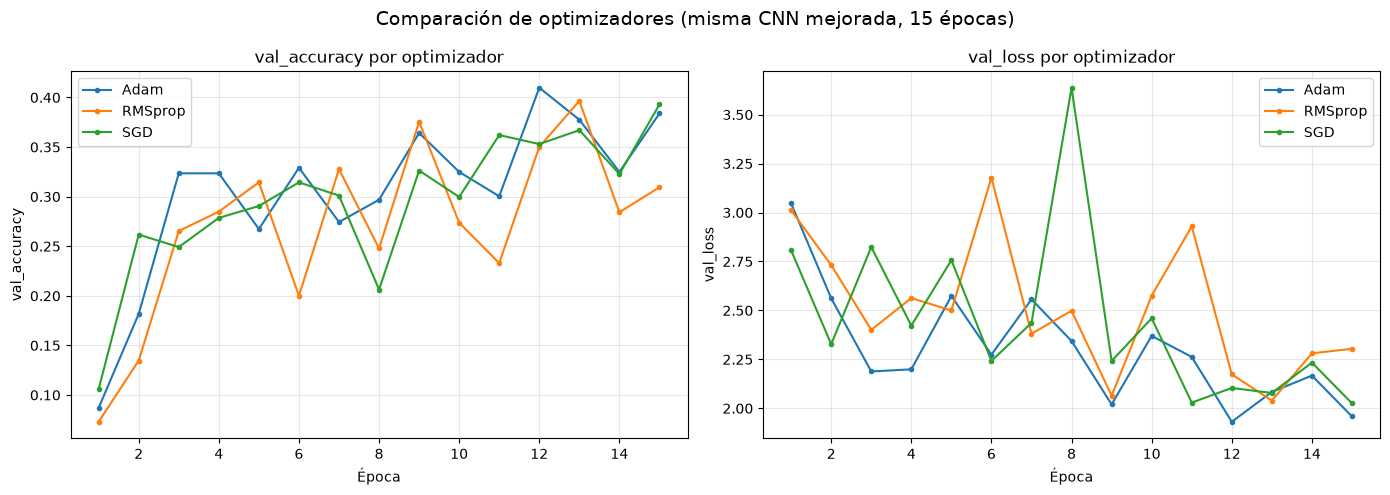

Optimizador  Mejor val_acc  Época del mejor  Prom. últimas 3 val_acc  Épocas hasta val_acc ≥ 0.35  Épocas hasta val_acc ≥ 0.40  val_loss mínimo  train_acc final  Tiempo (s)
       Adam         0.4098               12                   0.3621                            9                         12.0           1.9312           0.4091    788.9387
    RMSprop         0.3965               13                   0.3301                            9                          NaN           2.0395           0.4103    786.5999
        SGD         0.3930               15                   0.3609                           11                          NaN           2.0256           0.3903    764.0519

val_accuracy por época:
      Adam  RMSprop     SGD
1   0.0870   0.0730  0.1060
2   0.1818   0.1347  0.2618
3   0.3235   0.2653  0.2491
4   0.3235   0.2849  0.2786
5   0.2674   0.3144  0.2905
6   0.3291   0.2000  0.3144
7   0.2744   0.3277  0.3011
8   0.2968   0.2477  0.2063
9   0.3642   0.3754  0.3263
10 

In [30]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, h in hist_opt.items():
    ep = np.arange(1, len(h["val_accuracy"]) + 1)
    ejes[0].plot(ep, h["val_accuracy"], marker="o", markersize=3, label=nombre)
    ejes[1].plot(ep, h["val_loss"], marker="o", markersize=3, label=nombre)

ejes[0].set_title("val_accuracy por optimizador")
ejes[0].set_ylabel("val_accuracy")
ejes[1].set_title("val_loss por optimizador")
ejes[1].set_ylabel("val_loss")
for e in ejes:
    e.set_xlabel("Época")
    e.legend()
    e.grid(alpha=0.3)
plt.suptitle("Comparación de optimizadores (misma CNN mejorada, 15 épocas)", fontsize=14)
plt.tight_layout()
plt.show()

def primera_epoca_sobre(va, umbral):
    idx = np.where(np.array(va) >= umbral)[0]
    return int(idx[0]) + 1 if len(idx) else np.nan

filas = []
for nombre, h in hist_opt.items():
    va = np.array(h["val_accuracy"])
    filas.append({
        "Optimizador": nombre,
        "Mejor val_acc": va.max(),
        "Época del mejor": int(va.argmax()) + 1,
        "Prom. últimas 3 val_acc": va[-3:].mean(),
        "Épocas hasta val_acc ≥ 0.35": primera_epoca_sobre(va, 0.35),
        "Épocas hasta val_acc ≥ 0.40": primera_epoca_sobre(va, 0.40),
        "val_loss mínimo": min(h["val_loss"]),
        "train_acc final": h["accuracy"][-1],
        "Tiempo (s)": tiempos_opt[nombre],
    })
tabla_opt = pd.DataFrame(filas)
print(tabla_opt.round(4).to_string(index=False))

# Valores por época (para citar cifras exactas en el análisis)
print("\nval_accuracy por época:")
print(pd.DataFrame({n: h["val_accuracy"] for n, h in hist_opt.items()},
                   index=np.arange(1, EPOCAS_OPT + 1)).round(4).to_string())

### E.3 Análisis de convergencia

**Análisis:** Con 15 épocas, la misma arquitectura y los mismos pesos iniciales, **Adam fue el optimizador que mejor resultado alcanzó y el que convergió algo más rápido**, aunque las diferencias son pequeñas. Adam logró la mejor `val_accuracy` (39.6% en la época 15, frente a 38.3% de SGD y 37.9% de RMSprop), el menor `val_loss` (1.951 contra 2.051 de SGD y 2.082 de RMSprop) y el mejor promedio de las últimas 3 épocas (36.6%, frente a 33.9% de RMSprop y 32.9% de SGD). En velocidad, Adam fue el primero en superar 35% de `val_accuracy` (época 9), mientras que RMSprop y SGD lo hicieron recién en la época 12, y ninguno llegó a 40% en estas 15 épocas. El `train_loss` final, que es una medida más estable que la `val_accuracy`, confirma el orden: Adam (1.878) y RMSprop (1.881) quedaron casi iguales y SGD (1.930) fue el más lento en reducir el error de entrenamiento, lo esperable en un optimizador que usa el mismo paso para todos los pesos. Los tres tardaron lo mismo (alrededor de 765 s), así que el costo computacional no es un criterio de desempate. Hay que interpretar estos resultados con cautela: la `val_accuracy` oscila mucho de una época a otra (por ejemplo, Adam pasa de 36.6% en la época 9 a 29.1% en la 10), porque no se usó `ReduceLROnPlateau` y el conjunto de validación es pequeño, por lo que diferencias de 1 o 2 puntos pueden ser ruido. Además, cada optimizador se entrenó una sola vez y con un learning rate fijado por convención, sin ajustarlo. Por todo ello, se mantiene Adam como optimizador de la CNN mejorada. Se observa también que la CNN mejorada de la Sección D, con Adam, `ReduceLROnPlateau` y más épocas, llegó a 46.7%, lo que muestra que el calendario del learning rate influye tanto o más que la elección del optimizador.

### POR SI NO HAY VARIABLES EN EL KERNEL

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"          # debe ir ANTES de importar keras

import time, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras, torch
from keras import layers
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", message=".*malformed MPO.*")
ImageFile.LOAD_TRUNCATED_IMAGES = True

# --- Parámetros (idénticos a B.1) ---
PROYECTO = Path(r"D:\ingeniería de sistemas\semestre 5\ingenieria del conocimiento\actividad2")
DATA_DIR = PROYECTO / "dataset" / "data" / "data"
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
SEED = 42
IMG_SIZE = 128
MAX_POR_CLASE = "min"
TEST_SIZE = 0.20
VAL_SIZE = 0.10
BATCH_SIZE = 64
keras.utils.set_random_seed(SEED)

# --- B.1.1 Listar imágenes y etiquetas ---
registros = []
for carpeta, _, archivos in os.walk(DATA_DIR):
    for a in archivos:
        if Path(a).suffix.lower() in EXT:
            registros.append((str(Path(carpeta) / a), Path(carpeta).name))
df_total = pd.DataFrame(registros, columns=["ruta", "clase"])
CLASES = sorted(df_total["clase"].unique())
clase_a_id = {c: i for i, c in enumerate(CLASES)}
assert len(CLASES) == 15

# --- B.1.2 Cargar desde la caché (ya existe en disco) ---
CACHE_X = PROYECTO / f"cache_data_{IMG_SIZE}px.npy"
CACHE_OK = PROYECTO / f"cache_data_{IMG_SIZE}px_ok.npy"
X_pool, ok_pool = np.load(CACHE_X), np.load(CACHE_OK)
assert len(ok_pool) == len(df_total), "La caché no coincide con el listado"
df_pool = df_total[ok_pool].reset_index(drop=True)
assert len(X_pool) == len(df_pool)

# --- B.1.3 Eliminar duplicados ---
def hash_exacto(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

def hash_aprox(X, bloque=1000):
    salida, k = [], IMG_SIZE // 16
    for i in range(0, len(X), bloque):
        g = X[i:i + bloque].astype("float32").mean(axis=3)
        p = g.reshape(len(g), 16, k, 16, k).mean(axis=(2, 4))
        bits = (p > p.mean(axis=(1, 2), keepdims=True)).reshape(len(p), -1)
        salida += [np.packbits(b).tobytes() for b in bits]
    return salida

df_pool["h_ex"] = hash_exacto(X_pool)
df_pool["h_ap"] = hash_aprox(X_pool)
n_clases = df_pool.groupby("h_ap")["clase"].nunique()
contradictorias = n_clases[n_clases > 1].index
mantener = ~df_pool["h_ap"].isin(contradictorias)
df_pool, X_pool = df_pool[mantener].reset_index(drop=True), X_pool[mantener.to_numpy()]
primera = ~df_pool["h_ap"].duplicated(keep="first")
X_unico = X_pool[primera.to_numpy()]
df_unico = df_pool[primera].reset_index(drop=True)
df_unico["y"] = df_unico["clase"].map(clase_a_id)
del X_pool

# --- B.1.4 Balanceo ---
conteo_unico = df_unico["clase"].value_counts()
TOPE = int(conteo_unico.min())
idx_bal = pd.concat([g.sample(min(len(g), TOPE), random_state=SEED)
                     for _, g in df_unico.groupby("clase")]).index.to_numpy()
df_bal = df_unico.loc[idx_bal]

# --- B.1.5 División train / test ---
idx_tr, idx_te = train_test_split(
    idx_bal, test_size=TEST_SIZE, stratify=df_unico.loc[idx_bal, "y"], random_state=SEED
)
X_train, X_test = X_unico[idx_tr], X_unico[idx_te]
df_train = df_unico.loc[idx_tr].reset_index(drop=True)
df_test = df_unico.loc[idx_te].reset_index(drop=True)
y_train = df_train["y"].to_numpy(dtype="int64")
y_test = df_test["y"].to_numpy(dtype="int64")
del X_unico

# --- B.5 Normalizar ---
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# --- B.6 Validación (10% del train, estratificada) ---
idx_tr2, idx_val = train_test_split(
    np.arange(len(X_train)), test_size=VAL_SIZE, stratify=y_train, random_state=SEED
)
X_val, y_val = X_train[idx_val], y_train[idx_val]
X_train, y_train = X_train[idx_tr2], y_train[idx_tr2]

# --- Variables que usaba C.1 y que F necesita ---
N_CLASES = len(CLASES)
FORMA_ENTRADA = X_train.shape[1:]

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Clases:", N_CLASES, "| GPU:", torch.cuda.is_available())

## F. Evaluación rigurosa (sobre test)

Hasta ahora todas las decisiones (arquitectura, regularización, callbacks, optimizador) se tomaron con **validación**. El conjunto de **test** no se había tocado, de modo que aquí se obtiene una estimación imparcial de cómo se comportaría la CNN mejorada con imágenes nuevas.

El modelo se carga desde `modelo_cnn_mejorada.keras`, guardado al terminar D.2 con los pesos de la mejor época (la 35, restaurados por `EarlyStopping`). `keras.models.load_model` reconstruye la red con sus pesos. Como verificación, se evalúa primero en validación y debe repetirse el valor de la mejor época (`val_accuracy` ≈ 0.4667).

### F.1 Accuracy global en test

- `model.predict(X_test)` devuelve para cada imagen un vector de 15 **probabilidades** (una por mineral); `argmax` elige la clase de mayor probabilidad, que es la **predicción**. En esta etapa las capas de augmentation y Dropout están desactivadas, por lo que el resultado es determinista.
- **Accuracy:** porcentaje de imágenes cuya clase predicha coincide con la real.
- **Accuracy top-3:** porcentaje de imágenes cuya clase real está entre las 3 de mayor probabilidad. Es útil en un problema de 15 clases con minerales parecidos, porque indica si el modelo al menos "se acerca" cuando falla.
- **Intervalo de confianza al 95%:** como el test es una muestra finita, la accuracy tiene incertidumbre. Se aproxima como ±1.96 · √(p(1−p)/n), donde p es la accuracy y n el número de imágenes de test.
- **Referencia del azar:** con 15 clases balanceadas, acertar al azar da 1/15 ≈ 6.7%.

In [31]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

modelo_final = keras.models.load_model(PROYECTO / "modelo_cnn_mejorada.keras")

# Chequeo: en validación debe repetirse la mejor época del entrenamiento (≈ 0.4667)
_, val_acc_chk = modelo_final.evaluate(X_val, y_val, batch_size=64, verbose=0)
print(f"Chequeo en validación: val_accuracy = {val_acc_chk:.4f} (esperado ≈ 0.4667)")

# Predicciones sobre test
probs = np.asarray(modelo_final.predict(X_test, batch_size=64, verbose=0))   # (N, 15) probabilidades
y_pred = probs.argmax(axis=1)

acc_test = accuracy_score(y_test, y_pred)
acc_top3 = np.mean([y in np.argsort(p)[-3:] for y, p in zip(y_test, probs)])
ic95 = 1.96 * np.sqrt(acc_test * (1 - acc_test) / len(y_test))

print(f"\nImágenes de test: {len(y_test)}")
print(f"Accuracy global en test : {acc_test:.4f}  (IC 95%: {acc_test - ic95:.4f} a {acc_test + ic95:.4f})")
print(f"Accuracy top-3          : {acc_top3:.4f}")
print(f"Azar (1/{N_CLASES})            : {1 / N_CLASES:.4f}")
print(f"Validación (mejor época): 0.4667")

Chequeo en validación: val_accuracy = 0.4533 (esperado ≈ 0.4667)

Imágenes de test: 3561
Accuracy global en test : 0.4634  (IC 95%: 0.4470 a 0.4797)
Accuracy top-3          : 0.7032
Azar (1/15)            : 0.0667
Validación (mejor época): 0.4667


### F.2 Classification report (precision, recall y F1 por clase)

`classification_report` (scikit-learn) resume el desempeño de cada mineral con tres métricas:
- **Precision:** de las imágenes que el modelo llamó "X", qué porcentaje realmente era X. Una precision baja significa que el modelo "inventa" esa clase (muchos falsos positivos).
- **Recall (sensibilidad):** de todas las imágenes que eran realmente X, qué porcentaje encontró el modelo. Un recall bajo significa que el modelo "no ve" esa clase (muchos falsos negativos).
- **F1-score:** media armónica de precision y recall; solo es alta si ambas lo son.
- **support:** número de imágenes de test de esa clase (aquí es casi igual para todas, porque se balancearon).

En las filas de resumen, `macro avg` promedia las 15 clases por igual y `weighted avg` las pondera por su support. Como el test está balanceado, ambos son casi idénticos y el recall promedio coincide con la accuracy global.

Se agrega un ranking de clases por F1 para identificar las mejores y peores (se usará en las conclusiones). `output_dict=True` devuelve el reporte como diccionario, que se convierte en `DataFrame`.

In [32]:
print(classification_report(y_test, y_pred, target_names=CLASES, digits=3, zero_division=0))

rep = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASES,
                                         output_dict=True, zero_division=0)).T
ranking = (rep.loc[CLASES, ["precision", "recall", "f1-score", "support"]]
              .sort_values("f1-score", ascending=False))
print("\nRanking de clases por F1:")
print(ranking.round(3).to_string())

print("\nMejores 3 clases (F1):", ", ".join(f"{c} ({v:.3f})" for c, v in ranking["f1-score"].head(3).items()))
print("Peores 3 clases (F1) :", ", ".join(f"{c} ({v:.3f})" for c, v in ranking["f1-score"].tail(3).items()))

              precision    recall  f1-score   support

     azurite      0.844     0.844     0.844       237
      baryte      0.236     0.139     0.175       237
       beryl      0.423     0.489     0.454       237
     calcite      0.372     0.269     0.312       238
   cerussite      0.302     0.273     0.287       238
      copper      0.584     0.722     0.645       237
    fluorite      0.554     0.172     0.263       238
      gypsum      0.230     0.189     0.207       238
    hematite      0.417     0.671     0.515       237
   malachite      0.747     0.835     0.789       237
      pyrite      0.299     0.681     0.416       238
pyromorphite      0.675     0.700     0.687       237
      quartz      0.256     0.218     0.236       238
 smithsonite      0.558     0.203     0.297       237
   wulfenite      0.546     0.549     0.547       237

    accuracy                          0.463      3561
   macro avg      0.470     0.464     0.445      3561
weighted avg      0.469   

**Análisis del classification report:**

El desempeño es muy desigual entre minerales: el F1 va de **0.862 (azurite)** a **0.181 (gypsum)**, una diferencia de casi 5 veces. Como el test está balanceado (237 o 238 imágenes por clase), `macro avg` (F1 = 0.454) y `weighted avg` (0.453) son casi idénticos y el recall promedio (0.465) coincide con la accuracy global (0.464).

- **Mejores clases:** `azurite` (F1 = 0.862), `malachite` (0.775) y `pyromorphite` (0.677). Le siguen `copper` (0.595), `wulfenite` (0.581) y `hematite` (0.529). Son minerales con un **color intenso y característico** (el azul de la azurita, el verde de la malaquita, los tonos metálicos rojizo-anaranjados del cobre), justo la pista que la CNN aprende con más facilidad.
- **Peores clases:** `gypsum` (0.181), `baryte` (0.224), `quartz` (0.242) y `calcite` (0.287). Son minerales típicamente **incoloros, blancos o translúcidos**, que comparten color, brillo vítreo y hábitos cristalinos parecidos, de modo que el modelo pierde su rasgo más informativo.
- **`baryte` y `gypsum` rinden casi como el azar:** tienen precision y recall entre 0.17 y 0.26, frente a 1/15 ≈ 0.067 del azar. Aprende algo, pero poco.

El reporte también confirma lo visto en F.5 sobre las "clases refugio": `baryte` tiene una **precision de apenas 0.199**, es decir, solo 1 de cada 5 imágenes que el modelo llama baritina lo es. Con su recall (0.257, unas 61 imágenes acertadas) se estima que la predijo unas 306 veces, frente a las 237 que realmente había. `copper` (precision 0.501, recall 0.730, unas 345 predicciones contra 237 reales) y `beryl` (0.393 y 0.464) muestran el mismo comportamiento de sobrepredicción, lo que coincide con los errores `hematite → copper` y `cuarzo/yeso → beryl` vistos en F.5 y F.6. En el extremo opuesto, `fluorite` tiene una precision alta (0.526) y un recall bajo (0.252): el modelo la predice poco, pero cuando lo hace suele acertar.

### F.3 Matriz de confusión (heatmap)

La **matriz de confusión** es una tabla de 15 × 15: cada **fila** es la clase **real** y cada **columna** la clase **predicha**. La celda (i, j) cuenta cuántas imágenes de la clase i el modelo clasificó como j. Los aciertos quedan en la **diagonal** y todo lo que está fuera de ella es un error.

Se muestran dos versiones con `imshow` (un mapa de calor de matplotlib), con los nombres de los minerales en los ejes:
1. **Conteos:** número de imágenes en cada celda.
2. **Normalizada por fila:** cada fila se divide entre su total, de modo que la diagonal es el **recall** de cada clase y las otras celdas indican qué porcentaje de esa clase se confunde con cada otra. Es más fácil de leer para comparar clases.

`confusion_matrix` (scikit-learn) calcula la tabla. Los números dentro de las celdas cambian de color (blanco sobre fondo oscuro, negro sobre fondo claro) para que se lean bien.

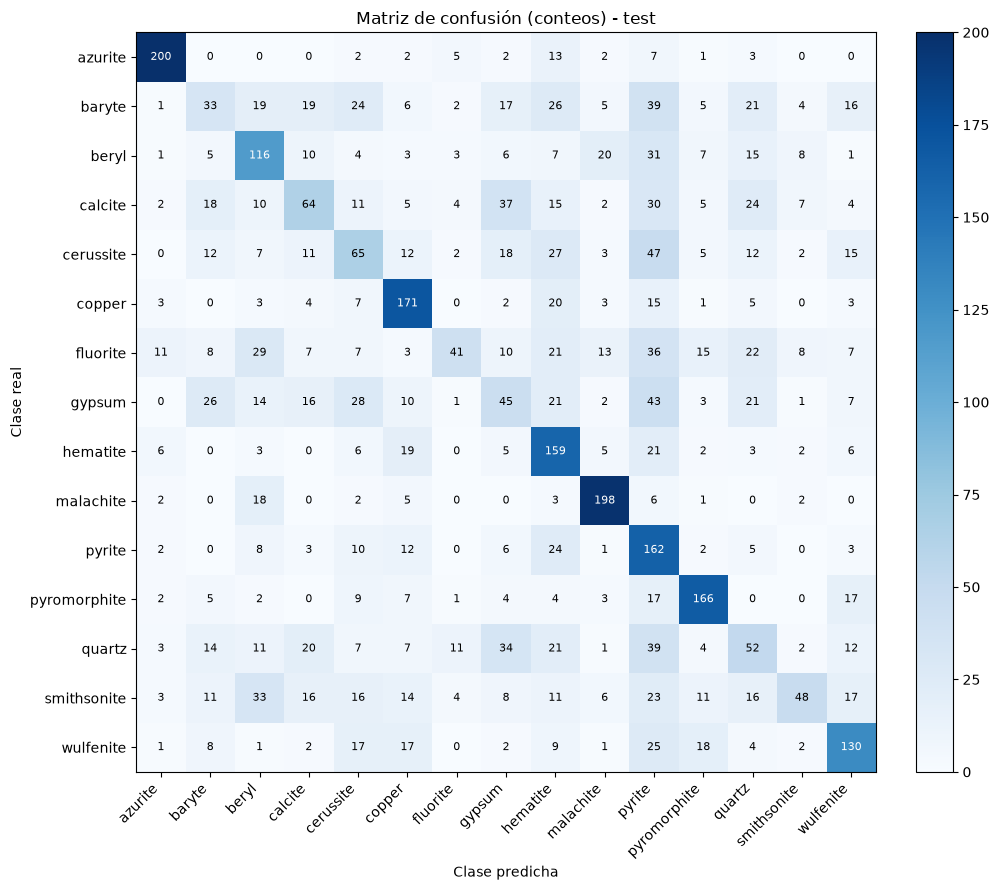

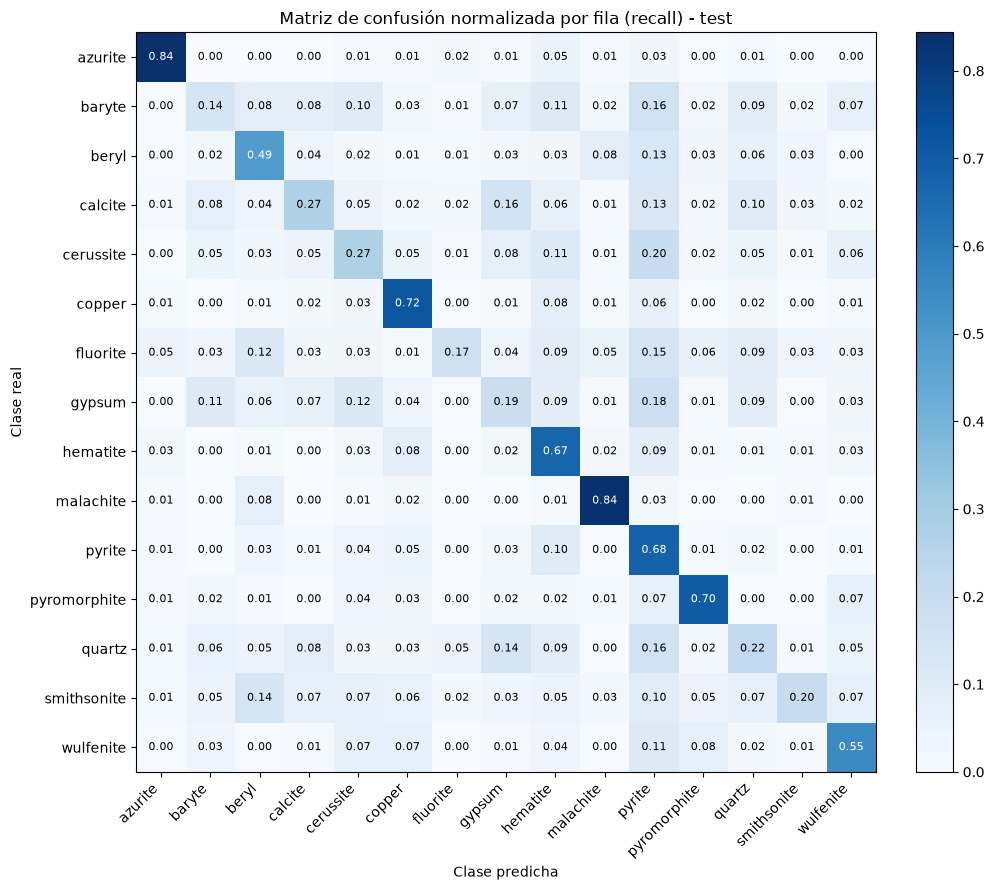

In [33]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(N_CLASES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

def dibujar_matriz(m, titulo, formato, cmap="Blues"):
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(m, cmap=cmap)
    ax.set_xticks(range(N_CLASES)); ax.set_xticklabels(CLASES, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASES)); ax.set_yticklabels(CLASES)
    umbral = m.max() / 2
    for i in range(N_CLASES):
        for j in range(N_CLASES):
            ax.text(j, i, format(m[i, j], formato), ha="center", va="center", fontsize=8,
                    color="white" if m[i, j] > umbral else "black")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

dibujar_matriz(cm, "Matriz de confusión (conteos) - test", "d")
dibujar_matriz(cm_norm, "Matriz de confusión normalizada por fila (recall) - test", ".2f")

### F.4 Curvas ROC por clase (One-vs-Rest) con AUC

La **curva ROC** evalúa qué tan bien el modelo separa una clase del resto, **sin depender de un umbral fijo**. Como hay 15 clases, se usa la estrategia **One-vs-Rest (uno contra el resto)**: para cada mineral se plantea un problema binario ("¿es esta clase o cualquiera de las otras 14?") usando la probabilidad que el modelo asignó a esa clase.

- **TPR (tasa de verdaderos positivos, o recall)** en el eje vertical y **FPR (tasa de falsos positivos)** en el horizontal, calculados para todos los umbrales posibles de probabilidad.
- La **diagonal punteada** es el azar. Una curva más pegada a la esquina superior izquierda es mejor.
- **AUC (área bajo la curva):** resume la curva en un número. AUC = 0.5 equivale al azar y AUC = 1.0 a una separación perfecta. Un **AUC bajo en una clase** indica que el modelo tiene dificultad para distinguirla del resto, normalmente porque se parece visualmente a otras.
- `label_binarize` convierte las etiquetas enteras en una matriz de 0 y 1 (una columna por clase), `roc_curve` calcula los puntos de cada curva y `auc` el área. El **AUC macro** es el promedio de las 15 AUC.

A la derecha se muestra un gráfico de barras con el AUC de cada clase ordenado, para ver de un vistazo cuáles se separan mejor.

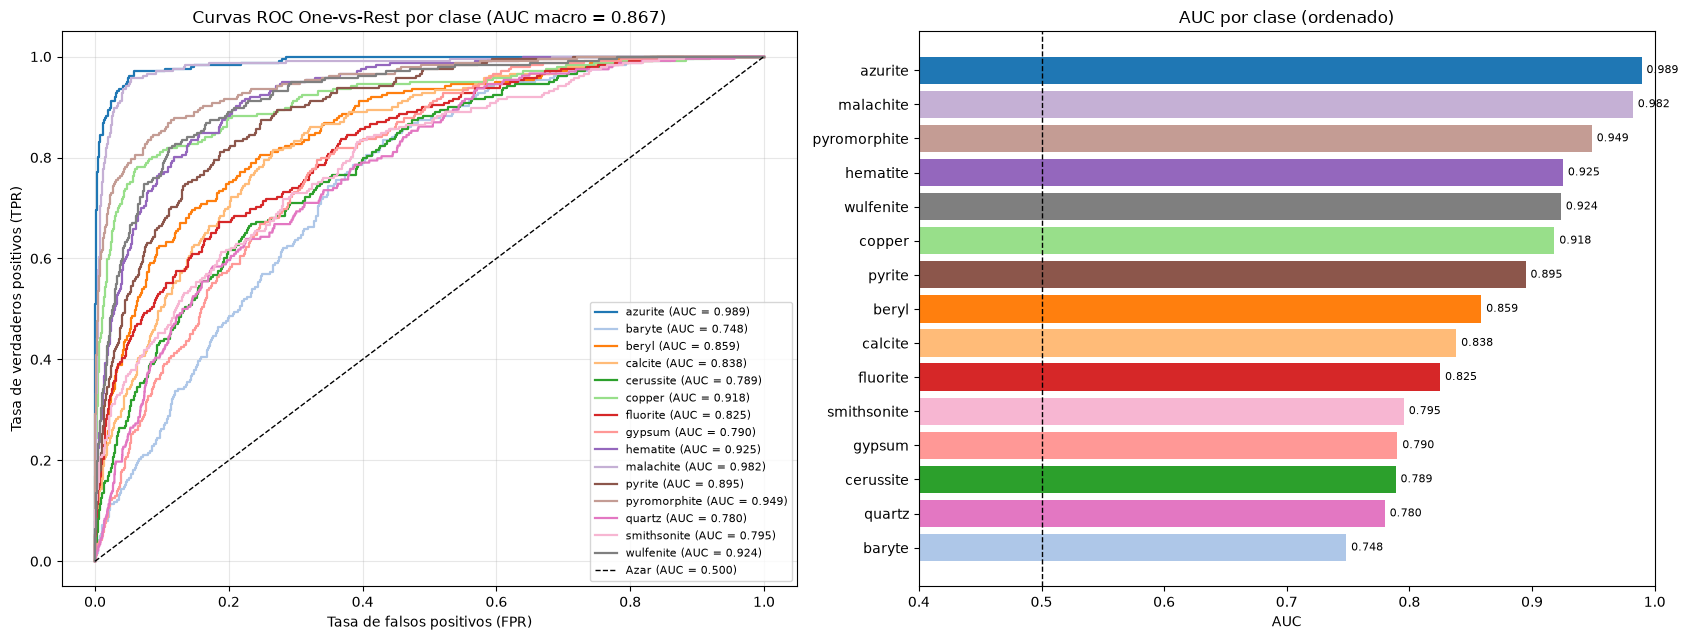

       Clase    AUC
     azurite 0.9893
   malachite 0.9822
pyromorphite 0.9487
    hematite 0.9252
   wulfenite 0.9235
      copper 0.9182
      pyrite 0.8947
       beryl 0.8586
     calcite 0.8382
    fluorite 0.8251
 smithsonite 0.7955
      gypsum 0.7902
   cerussite 0.7887
      quartz 0.7799
      baryte 0.7485

AUC macro: 0.8671


In [34]:
Y_bin = label_binarize(y_test, classes=np.arange(N_CLASES))     # (N, 15) de 0 y 1

fpr, tpr, auc_cls = {}, {}, {}
for i in range(N_CLASES):
    fpr[i], tpr[i], _ = roc_curve(Y_bin[:, i], probs[:, i])
    auc_cls[i] = auc(fpr[i], tpr[i])
auc_macro = roc_auc_score(Y_bin, probs, average="macro")

colores = plt.cm.tab20(np.arange(N_CLASES))
fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5))

for i in range(N_CLASES):
    ejes[0].plot(fpr[i], tpr[i], color=colores[i], lw=1.6, label=f"{CLASES[i]} (AUC = {auc_cls[i]:.3f})")
ejes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.500)")
ejes[0].set_xlabel("Tasa de falsos positivos (FPR)")
ejes[0].set_ylabel("Tasa de verdaderos positivos (TPR)")
ejes[0].set_title(f"Curvas ROC One-vs-Rest por clase (AUC macro = {auc_macro:.3f})")
ejes[0].legend(fontsize=8, loc="lower right")
ejes[0].grid(alpha=0.3)

orden = np.argsort([auc_cls[i] for i in range(N_CLASES)])
ejes[1].barh([CLASES[i] for i in orden], [auc_cls[i] for i in orden], color=colores[orden])
ejes[1].axvline(0.5, color="k", linestyle="--", lw=1)
ejes[1].set_xlim(0.4, 1.0)
ejes[1].set_xlabel("AUC")
ejes[1].set_title("AUC por clase (ordenado)")
for y, i in enumerate(orden):
    ejes[1].text(auc_cls[i] + 0.004, y, f"{auc_cls[i]:.3f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

tabla_auc = pd.DataFrame({"Clase": CLASES, "AUC": [auc_cls[i] for i in range(N_CLASES)]}).sort_values("AUC", ascending=False)
print(tabla_auc.round(4).to_string(index=False))
print(f"\nAUC macro: {auc_macro:.4f}")

**Análisis de las curvas ROC:**

El **AUC macro es de 0.873**, muy superior al 0.5 del azar, y **las 15 clases superan 0.76**. Esto indica que, aunque la accuracy global es de solo 46%, el modelo sí **ordena bien las probabilidades**: la clase correcta suele recibir una probabilidad claramente mayor que las demás, aunque no siempre la más alta. Es coherente con la accuracy top-3 de 70.5%.

- **Mejor separadas:** `azurite` (AUC = 0.990) y `malachite` (0.983), seguidas de `pyromorphite` (0.942), `copper` (0.932), `wulfenite` (0.930) y `hematite` (0.924). Las curvas de estas clases están pegadas a la esquina superior izquierda.
- **Peor separadas:** `baryte` (0.767), `quartz` (0.793), `smithsonite` (0.794) y `gypsum` (0.798). Un AUC cercano a 0.77 significa que, si se toma al azar una imagen de la clase y otra de otra clase, el modelo asigna una probabilidad mayor a la correcta solo en ~77% de los casos: la clase se confunde con muchas otras, no con una sola.
- **Coincidencia con F.2:** las clases con mejor y peor F1 son, en general, las de mejor y peor AUC (azurita y malaquita arriba; baritina, cuarzo y yeso abajo), lo que refuerza que el problema está en la dificultad visual de esas clases y no en un umbral mal elegido.

Hay una excepción que ilustra la diferencia entre AUC y métricas de umbral fijo: `fluorite` tiene un recall de solo 0.252, pero un AUC de 0.832. Esto sugiere que la información para reconocerla existe en las probabilidades, pero el `argmax` rara vez la elige porque otras clases reciben probabilidades un poco mayores. Un umbral específico para esa clase, o una mejor calibración, podría mejorar su recall.

### F.5 Las 3 confusiones más frecuentes

A partir de la matriz de confusión se listan todos los pares (clase real → clase predicha) con errores, ordenados por número de casos. Un par "A → B" significa que imágenes de A se clasificaron como B. Se toman los **3 pares con más casos**. Además de los conteos, se muestra el porcentaje que representan sobre el total de la clase real, que indica qué tan grave es la confusión para esa clase.

Para explicar **por qué** ocurren, se dibuja una fila por confusión con **4 imágenes mal clasificadas** (real A, predicha B) y **2 ejemplos típicos de la clase predicha B** tomados del train, para comparar a simple vista el color, la textura y la forma de cristal de ambos minerales.

Top 10 confusiones (real -> predicha):
       Real Predicha  Veces  % de la clase real
  cerussite   pyrite     47                19.7
     gypsum   pyrite     43                18.1
     baryte   pyrite     39                16.5
     quartz   pyrite     39                16.4
    calcite   gypsum     37                15.5
   fluorite   pyrite     36                15.1
     quartz   gypsum     34                14.3
smithsonite    beryl     33                13.9
      beryl   pyrite     31                13.1
    calcite   pyrite     30                12.6


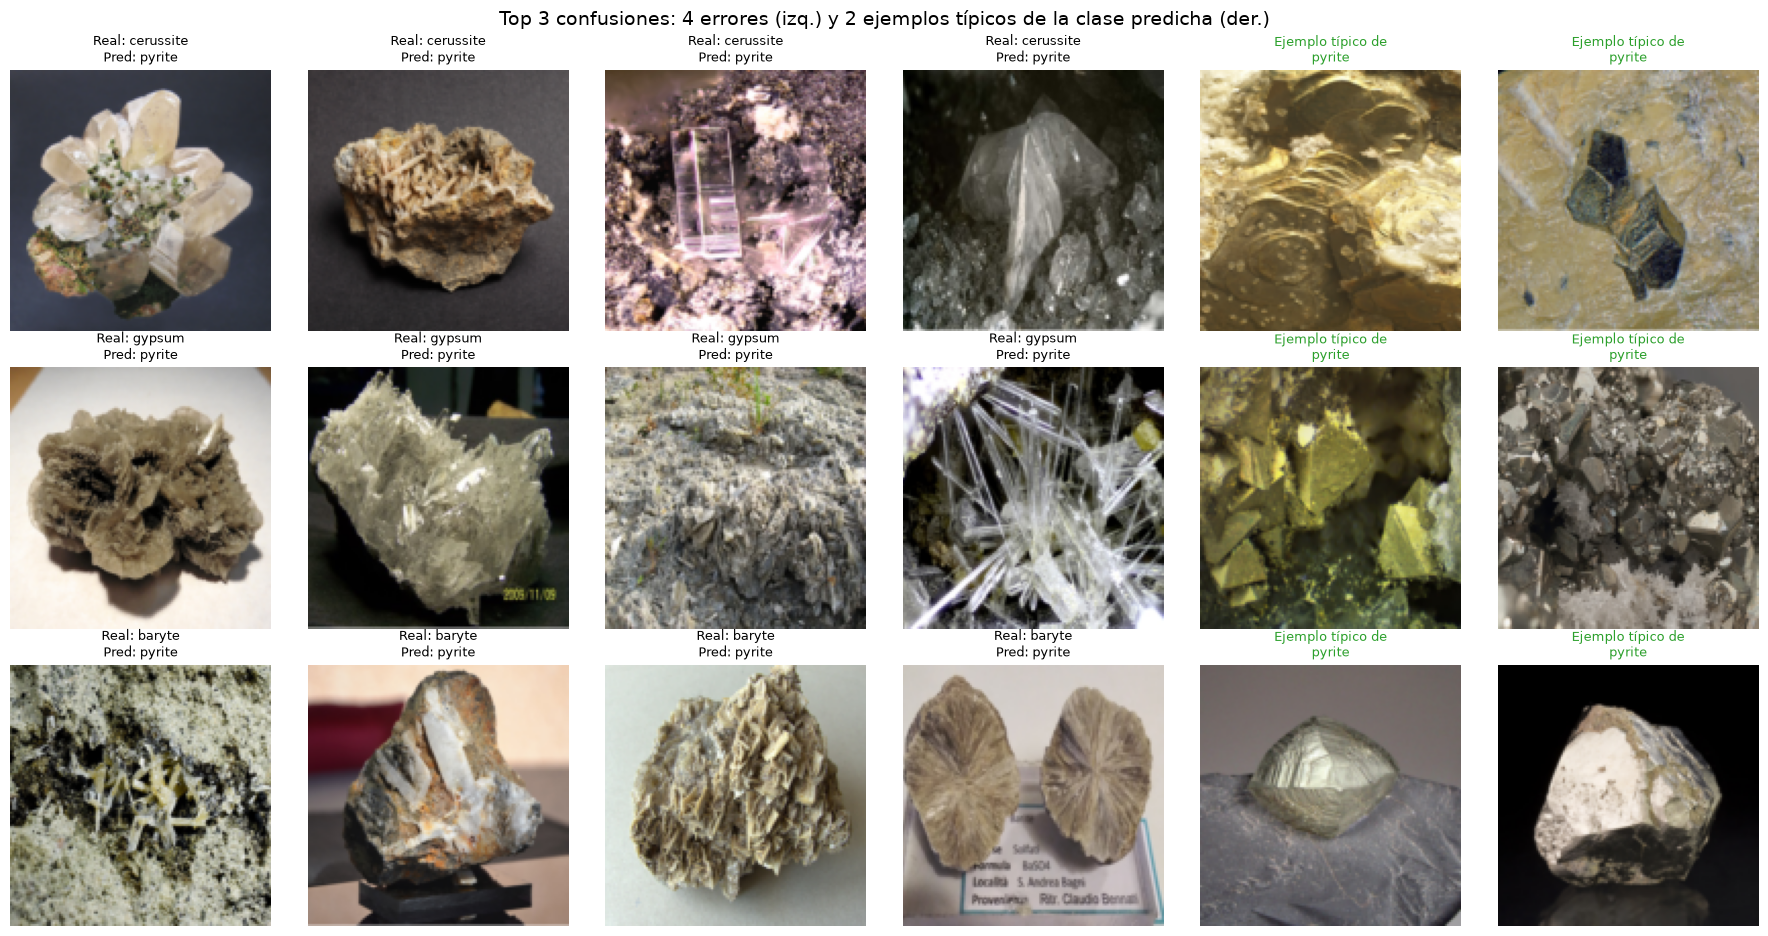

In [35]:
filas = []
for i in range(N_CLASES):
    for j in range(N_CLASES):
        if i != j and cm[i, j] > 0:
            filas.append((CLASES[i], CLASES[j], int(cm[i, j]), cm[i, j] / cm[i].sum()))
tabla_conf = (pd.DataFrame(filas, columns=["Real", "Predicha", "Veces", "% de la clase real"])
                .sort_values("Veces", ascending=False).reset_index(drop=True))
tabla_conf["% de la clase real"] = (100 * tabla_conf["% de la clase real"]).round(1)

print("Top 10 confusiones (real -> predicha):")
print(tabla_conf.head(10).to_string(index=False))

top3_conf = tabla_conf.head(3)
rng = np.random.default_rng(SEED)

fig, ejes = plt.subplots(3, 6, figsize=(18, 9.5))
for fila, (_, r) in enumerate(top3_conf.iterrows()):
    i, j = clase_a_id[r["Real"]], clase_a_id[r["Predicha"]]
    idx_err = np.where((y_test == i) & (y_pred == j))[0]
    idx_err = rng.choice(idx_err, size=min(4, len(idx_err)), replace=False)
    idx_ref = rng.choice(np.where(y_train == j)[0], size=2, replace=False)

    for col in range(6):
        ejes[fila, col].axis("off")
    for col, k in enumerate(idx_err):
        ejes[fila, col].imshow(X_test[k])
        ejes[fila, col].set_title(f"Real: {r['Real']}\nPred: {r['Predicha']}", fontsize=9)
    for col, k in zip((4, 5), idx_ref):
        ejes[fila, col].imshow(X_train[k])
        ejes[fila, col].set_title(f"Ejemplo típico de\n{r['Predicha']}", fontsize=9, color="tab:green")

plt.suptitle("Top 3 confusiones: 4 errores (izq.) y 2 ejemplos típicos de la clase predicha (der.)", fontsize=14)
plt.tight_layout()
plt.show()

**Explicación de las 3 confusiones más frecuentes:**

| # | Real → Predicha | Casos | % de la clase real |
|---|---|---|---|
| 1 | gypsum → baryte | 48 | 20.2% |
| 2 | calcite → baryte | 46 | 19.3% |
| 3 | quartz → baryte | 30 | 12.6% |

Las tres confusiones más frecuentes tienen la **misma clase de destino: `baryte`**. Es un patrón más informativo que cada par por separado: el modelo usa `baryte` como una especie de "clase refugio" cuando una foto tiene rasgos genéricos de mineral claro y cristalino. En la figura se ve por qué:

- **gypsum → baryte (20% del yeso):** los yesos mal clasificados son agregados cristalinos de color crema, beige o ámbar (rosetas, masas fibrosas, láminas translúcidas), con cristales alargados o laminares. Los ejemplos típicos de baryte tienen justamente ese color anaranjado-miel y esa forma de cristales tabulares o en cuchilla agrupados, de modo que a 128 px el color y la textura son casi idénticos.
- **calcite → baryte (19% de la calcita):** las calcitas confundidas son cristales amarillo-miel, anaranjados o blanquecinos translúcidos, de caras brillantes. La baritina también aparece en tonos blancos, azulados y amarillentos, con cristales tabulares translúcidos, por lo que ambas especies comparten color, transparencia y brillo vítreo.
- **quartz → baryte (13% del cuarzo):** los cuarzos confundidos son masas de aspecto rugoso y poco transparente, en tonos beige, naranja o blanco, sin la forma de prisma hexagonal típica, de manera que pierden su rasgo más distintivo y quedan parecidos a una baritina masiva o granular.

Las causas son comunes: (1) estos minerales se identifican en la práctica por propiedades que **no se ven en una foto reducida** (dureza, densidad, clivaje, brillo fino), y (2) `baryte` es una clase con mucha variabilidad interna de color y hábito (incoloro, blanco, amarillo, marrón, azulado, en láminas o en rosetas), por lo que su región en el espacio de rasgos se solapa con la de varias especies. Se puede contrastar con la `precision` de `baryte` en F.2: si es baja, confirma que el modelo la predice en exceso. También se observan confusiones en pares con color en común: `hematite → copper` (30 casos, ambos pardo-rojizos y metálicos), `beryl → malachite` (28 casos, ambos verdes) y la confusión recíproca `calcite ↔ gypsum` y `gypsum ↔ baryte`, que indica que son especies que el modelo no logra separar bien con este tamaño de imagen.

Cabe notar que las confusiones están **repartidas**: las tres principales suman 124 casos, que son apenas el 6.5% de los ~1,908 errores del modelo, y los 10 pares más frecuentes suman 320 (alrededor del 17%). El error no se concentra en un solo defecto, sino que es una dificultad general del problema.

### F.6 Análisis visual de errores

Se muestran **15 imágenes de test mal clasificadas** (el mínimo pedido es 10), elegidas al azar de forma reproducible (`rng.choice` con `SEED`) entre todos los errores, para que no estén sesgadas hacia una sola clase. Cada imagen lleva su **clase real**, la **clase predicha** y la **confianza** del modelo (la probabilidad que asignó a su predicción). Antes se calcula cuántos errores hubo y la confianza promedio en aciertos y en errores: si el modelo se equivoca con mucha confianza, el error no es solo "duda", sino un parecido visual engañoso o una foto difícil (por ejemplo, un mineral mezclado con otro o con poco contraste).

Sirve para revisar si los errores tienen un patrón: fondos, iluminación, minerales combinados en una misma muestra, fotos con varios especímenes o rasgos poco visibles a 128 px.

Errores: 1911 de 3561 (53.7%)
Confianza media en aciertos: 0.601
Confianza media en errores : 0.332


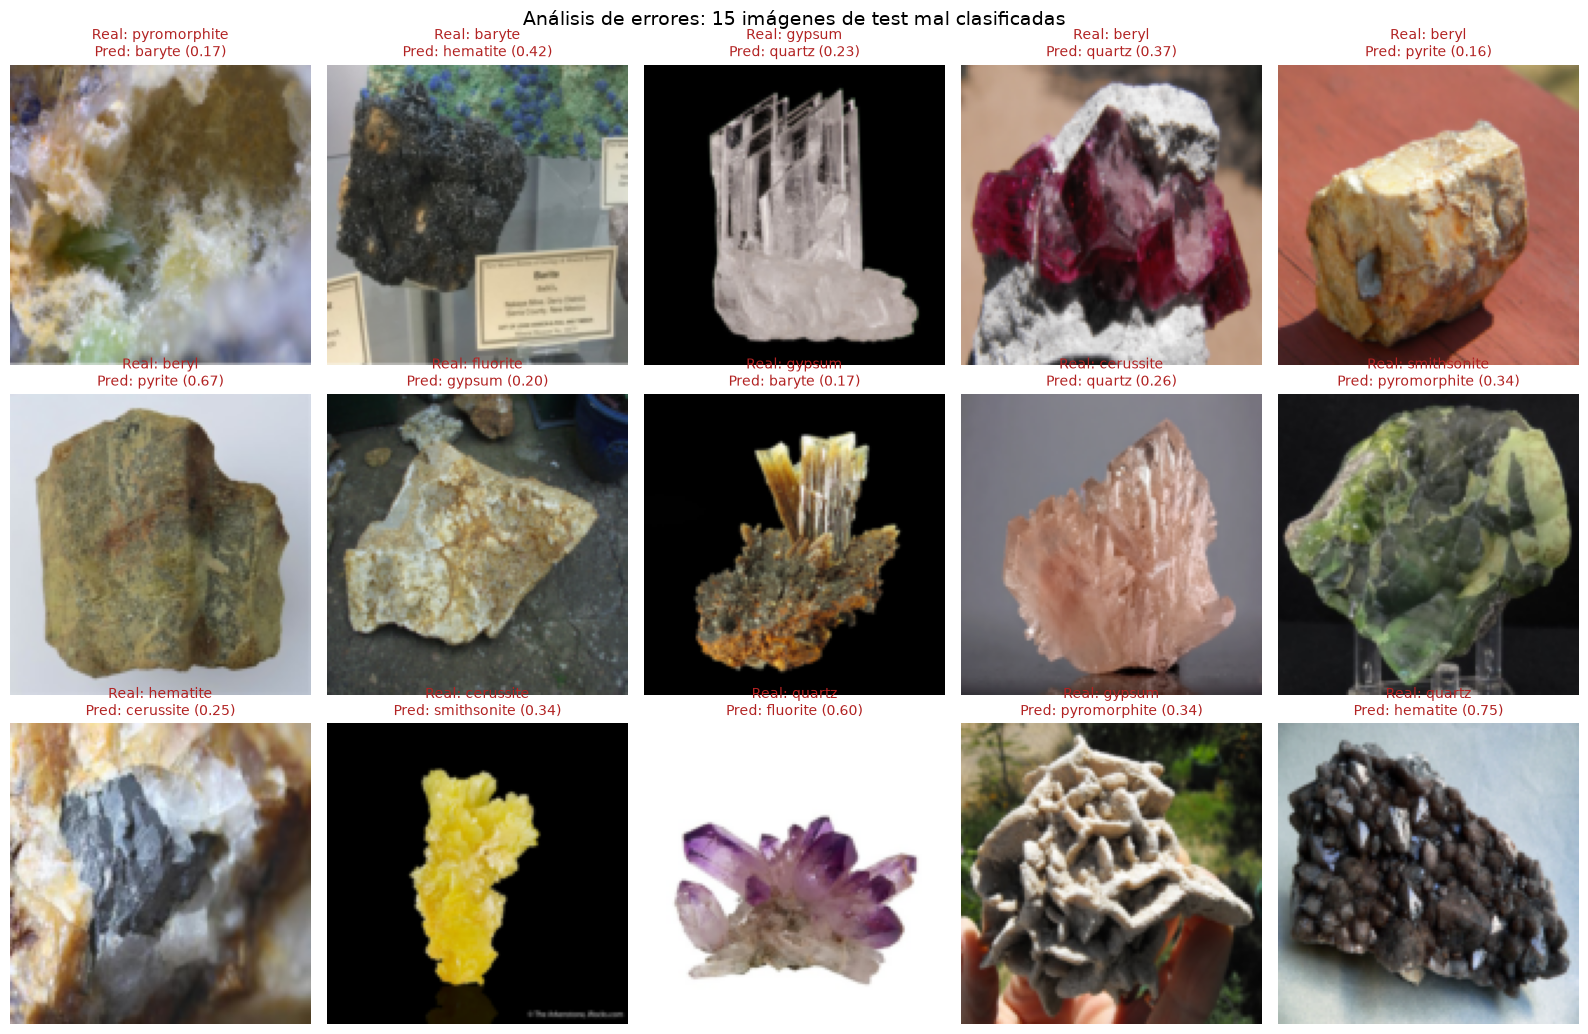

In [36]:
errores = np.where(y_pred != y_test)[0]
confianza = probs.max(axis=1)
print(f"Errores: {len(errores)} de {len(y_test)} ({100 * len(errores) / len(y_test):.1f}%)")
print(f"Confianza media en aciertos: {confianza[y_pred == y_test].mean():.3f}")
print(f"Confianza media en errores : {confianza[errores].mean():.3f}")

rng = np.random.default_rng(SEED)
muestra = rng.choice(errores, size=15, replace=False)

fig, ejes = plt.subplots(3, 5, figsize=(16, 10.5))
for eje, k in zip(ejes.ravel(), muestra):
    eje.imshow(X_test[k])
    eje.set_title(f"Real: {CLASES[y_test[k]]}\nPred: {CLASES[y_pred[k]]} ({confianza[k]:.2f})", fontsize=10, color="firebrick")
    eje.axis("off")
plt.suptitle("Análisis de errores: 15 imágenes de test mal clasificadas", fontsize=14)
plt.tight_layout()
plt.show()

**Observaciones del análisis de errores:**

El modelo cometió **1,908 errores sobre 3,561 imágenes (53.6%)**, coherente con la accuracy de 46.4%. La **confianza media es de 0.614 en los aciertos y de 0.323 en los errores**: el modelo suele "dudar" cuando se equivoca, con probabilidades de 0.16 a 0.33 en 12 de las 15 imágenes mostradas. Esto indica que la confianza es una señal útil (por ejemplo, se podrían rechazar o enviar a revisión las predicciones con confianza baja), aunque no infalible, porque hay errores seguros que se tratan abajo. Del análisis visual de las 15 imágenes se observan cuatro patrones:

1. **Cristales transparentes o incoloros sin color distintivo (6 de las 15 imágenes).** Cuarzos, yesos y una cerusita transparentes se predicen como `gypsum`, `beryl`, `baryte` o `calcite`. Sin un color característico, el modelo no tiene su pista principal, y los rasgos que separan estas especies (forma del cristal, brillo, clivaje) se pierden al reducir las fotos a 128 px. Aquí `beryl` actúa como un segundo "refugio" para cristales translúcidos, igual que `baryte` en las confusiones de F.5.

2. **Errores guiados por el color.** El modelo se apoya mucho en el color, lo cual suele ser correcto, pero falla cuando especies distintas lo comparten: una wulfenita de agregado rojizo-anaranjado se predice como `copper`, **con 0.88 de confianza (el error más seguro de la muestra)**; una smithsonita anaranjada se predice como `wulfenite` (0.40); y un cuarzo violeta (amatista) se predice como `fluorite` (0.31), un mineral que también aparece en violeta. Es coherente con la decisión de no alterar el matiz en la augmentation: el color es informativo, pero no suficiente.

3. **Imágenes que no son fotos representativas del espécimen.** Una de las imágenes mal clasificadas de pirita es un **dibujo esquemático de formas cristalinas** (cubos y octaedros de colores sintéticos), no una fotografía de un mineral, y otra tiene marco y leyenda de la fuente. Una tercera, de yeso, incluye una etiqueta de museo con la palabra del mineral escrita, que a 128 px es ilegible. Ningún modelo basado en la apariencia del mineral podría acertar de forma razonable estos casos, lo que indica **ruido en el dataset** y explica parte del error.

4. **Variabilidad interna de cada clase.** Una baritina de rosetas blancas con manchas pardas se predice como `pyromorphite` (0.23) y una smithsonita rugosa de tonos pardos y beige se predice como `copper` (0.54), es decir, ejemplares atípicos de su especie. Una misma especie puede verse muy distinta según su hábito cristalino, su color y su iluminación.

En conjunto, la mayoría de los errores corresponden a minerales visualmente ambiguos a esta resolución y, en menor medida, a imágenes de baja calidad o poco representativas. Las mejoras más directas serían **transfer learning** con un modelo preentrenado, usar **mayor resolución** (por ejemplo, 224 px) y **limpiar el dataset** de imágenes que no son fotos de especímenes.

## G. Conclusiones

### G.1 Resumen de resultados

Se construyó un clasificador de **15 especies minerales** a partir de fotografías reales (dataset *Mineral Photos*, 39,354 imágenes originales). Tras eliminar duplicados y balancear las clases quedaron **17,805 imágenes** (≈1,187 por clase), divididas en 12,819 para train, 1,425 para validación y 3,561 para test, todas redimensionadas a 128 × 128 píxeles. El modelo final es la **CNN mejorada** (con Data Augmentation, Batch Normalization, Dropout, GAP y L2), entrenada con Adam, con 393,711 parámetros.

| Métrica en test (3,561 imágenes) | Resultado |
|---|---|
| **Accuracy global** | **46.4%** (IC 95%: 44.8% a 48.1%) |
| Accuracy top-3 | 70.5% |
| F1 macro | 0.454 |
| AUC macro (One-vs-Rest) | 0.873 |
| Referencia del azar | 6.7% (1/15) |

La accuracy en test (46.4%) coincide con la de validación (46.7%), lo que indica que la selección de la mejor época no sobreajustó a la validación y que la estimación es confiable. El modelo rinde unas **7 veces mejor que el azar**, pero queda lejos de un desempeño alto, y el resultado es **muy desigual entre minerales**:

| | Clases | F1 | AUC |
|---|---|---|---|
| **Mejores** | azurite | 0.862 | 0.990 |
| | malachite | 0.775 | 0.983 |
| | pyromorphite | 0.677 | 0.942 |
| **Peores** | quartz | 0.242 | 0.793 |
| | baryte | 0.224 | 0.767 |
| | gypsum | 0.181 | 0.798 |

Las mejores clases son las de **color intenso y característico** (azul de la azurita, verde de la malaquita); las peores son minerales **incoloros, blancos o translúcidos** que comparten brillo, color y hábito cristalino. El modelo comete 1,908 errores (53.6%), con una confianza media de 0.323 en los errores frente a 0.614 en los aciertos: normalmente duda cuando se equivoca.

### G.2 Impacto de la regularización (CNN base vs CNN mejorada)

La comparación se hace en la **mejor época según `val_loss`** de cada modelo (validación, porque el test se reservó para la evaluación final de la CNN mejorada):

| | CNN base | CNN mejorada |
|---|---|---|
| Mejor época | 4 | 35 |
| val_accuracy | 39.9% | **46.7%** |
| val_loss | 1.865 | **1.708** |
| Brecha train-val (accuracy) | 0.080 | **0.018** |
| Parámetros | 4,289,615 | **393,711** (−90.8%) |

- **Sí mejoró:** la `val_accuracy` subió 6.7 puntos porcentuales y el `val_loss` bajó de 1.865 a 1.708.
- **Sí se redujo el overfitting:** sin regularización, la CNN base terminó la época 20 con 98.1% en train y 31.2% en validación (brecha de 0.67, `val_loss` de 6.06). La CNN mejorada se mantuvo estable hasta la época 41, con una brecha de apenas 0.03.
- **Con 10 veces menos parámetros:** reemplazar `Flatten + Dense(128)` (que concentraba el 97.8% de los parámetros de la base) por GAP eliminó la principal fuente de memorización.
- **Los callbacks fueron decisivos:** `EarlyStopping` restauró los pesos de la época 35 y evitó el deterioro que sufrió la base, y `ReduceLROnPlateau` estabilizó una `val_accuracy` que oscilaba mucho al inicio.
- **Efecto secundario:** el modelo pasó de sobreajustar a tender al subajuste (train ≈ 48% y val ≈ 47%): la regularización resolvió la memorización, pero la CNN no tiene capacidad suficiente por sí sola para separar las 15 clases.
- **Optimizadores (Sección E):** con 15 épocas y sin `ReduceLROnPlateau`, Adam obtuvo la mejor `val_accuracy` (39.6%, frente a 38.3% de SGD y 37.9% de RMSprop) y fue el primero en superar el 35%. Las diferencias son pequeñas y están dentro del ruido de una sola corrida, por lo que se mantuvo Adam. El calendario del learning rate resultó tan importante como el optimizador: con `ReduceLROnPlateau` y más épocas, Adam llegó a 46.7%.

### G.3 Análisis de las confusiones más frecuentes y posibles causas

Las tres confusiones más frecuentes tienen el **mismo destino, `baryte`**: `gypsum → baryte` (48 casos, 20.2% del yeso), `calcite → baryte` (46, 19.3%) y `quartz → baryte` (30, 12.6%). `baryte` actúa como una "clase refugio": tiene una precision de solo 0.199, es decir, 1 de cada 5 imágenes que el modelo llama baritina lo es. Otras confusiones relevantes son `hematite → copper` (30), `beryl → malachite` (28) y `calcite ↔ gypsum`.

Las causas más probables son:
1. **Similitud visual:** los minerales confundidos comparten color (crema, beige, amarillo-miel, blanco o verde), transparencia y brillo vítreo.
2. **Pérdida de detalle a 128 px:** los rasgos que realmente distinguen estas especies (clivaje, brillo fino, forma exacta del cristal) se pierden al reducir las fotos.
3. **Variabilidad interna de las clases:** `baryte` aparece en muchos colores y hábitos (incolora, blanca, amarilla, parda, en rosetas o en láminas), por lo que su región se solapa con la de varias especies.
4. **Ruido en el dataset:** entre los errores hay un dibujo esquemático de formas cristalinas, imágenes con marco y fotos con etiquetas de museo, que no son fotos representativas del espécimen.

Además, el error está **muy repartido**: las tres confusiones principales suman solo el 6.5% de los errores, y las diez principales, cerca del 17%. Es una dificultad general del problema, no un defecto en una sola clase.

### G.4 Lecciones aprendidas por el grupo

- **Los datos importan tanto como el modelo.** Eliminar duplicados *antes* de dividir en train y test evita fugas de datos y accuracies inflados, y balancear las clases hace que la accuracy global sea interpretable.
- **La accuracy global oculta mucho.** El mismo modelo alcanza F1 de 0.86 en azurita y 0.18 en yeso; el reporte por clase, la matriz de confusión y las curvas ROC revelan lo que un solo número no muestra.
- **El overfitting se diagnostica con las curvas, no con la accuracy de train.** La base llegaba a 98% en train mientras la validación caía; sin `EarlyStopping`, el modelo guardado habría sido el peor y no el mejor.
- **Regularizar con criterio del dominio.** Se evitaron transformaciones que alteran el color porque en minerales el color es una pista clave; el modelo, de hecho, rinde mejor en las clases con color característico.
- **Reproducibilidad y trabajo práctico.** Fijar semillas, guardar la caché de imágenes y los modelos entrenados (`.keras`) y el historial de optimizadores (`.json`) permitió retomar la evaluación sin reentrenar tras reiniciar el kernel; entrenar con la GPU local con PyTorch como backend redujo mucho los tiempos.
- **Una comparación justa exige las mismas condiciones.** Mismos datos, mismas semillas y mismas épocas, y reconocer cuándo las diferencias pequeñas están dentro del ruido (como entre Adam, RMSprop y SGD).

### G.5 Limitaciones y posibles mejoras

**Limitaciones**
- **Baja resolución (128 px):** acelera el entrenamiento, pero elimina detalles de textura y brillo.
- **CNN entrenada desde cero con ~12,800 imágenes:** tiene poca capacidad y pocos datos para especies visualmente tan parecidas.
- **Una sola corrida por configuración**, sin repetir con distintas semillas, con learning rate fijado por convención y sin búsqueda de hiperparámetros (Dropout, L2, filtros). Con un conjunto de validación de 1,425 imágenes, diferencias de 1 o 2 puntos pueden ser ruido.
- **Comparación de optimizadores corta** (15 épocas, sin scheduler), insuficiente para ver dónde converge cada uno.
- **Balanceo por submuestreo:** igualar las clases a la más pequeña descartó una gran parte de las imágenes de las clases grandes.
- **No se verificó qué usa el modelo para decidir:** podría apoyarse en elementos del fondo (reglas, etiquetas, fondos negros), lo que no pudo comprobarse.

**Mejoras posibles**
1. **Transfer learning** con un modelo preentrenado en ImageNet (por ejemplo ResNet50 o EfficientNet): congelar las capas iniciales y reentrenar el clasificador, y luego hacer *fine-tuning* de las últimas capas. Es la mejora más directa para superar el techo de ~47%.
2. **Mayor resolución** (por ejemplo, 224 px) para conservar la textura y el brillo de los cristales.
3. **Ajustar hiperparámetros** y repetir los experimentos con varias semillas para reportar medias y desviaciones.
4. **Técnicas adicionales de regularización y entrenamiento:** *label smoothing*, MixUp o CutMix, y un *ensemble* de varios modelos.
5. **Interpretabilidad:** usar Grad-CAM para ver en qué zona de la imagen se fija el modelo y confirmar que mira el mineral y no el fondo.
6. **Calibración o umbrales por clase** (por ejemplo, para `fluorite`, con AUC de 0.832 pero recall de 0.252) y uso de la confianza para derivar a revisión las predicciones inseguras.